# DATA CHALLENGE 2
#### PROJET 1 : prédiction de survenue (oui ou non) d'exacerbations de l'asthme, pour chaque patient, dans l'année suivant le début du traitement.

Notre objectif est de construire un *pipeline* de *machine learning* qui pourra fonctionner sur un fichier de même structure que le fichier de données initial ("trainDataDC2.csv.gz") et qui nous donnera, en sortie, la prédiction de survenue (oui ou non) d'exacerbations de l'asthme, pour chaque patient, dans l'année suivant le début du traitement.

Ce notebook rassemble les trois notebooks précédents (bagging, boosting, forêt aléatoire) en une seule étude comparative. Les données, le préprocessing, la validation croisée, le réglage des hyperparamètres, le réglage du seuil et l'évaluation finale sont écrits **une seule fois**, puis appliqués aux trois méthodes par une boucle. Les trois modèles partagent donc exactement la même partition des données, le même préprocesseur et le même protocole d'évaluation : les écarts observés viennent de la méthode d'ensemble, non du protocole.

**Plan**

1. Importation des données
2. Partitionner les données
3. Préprocessing
4. Les trois méthodes d'ensemble : principe, hyperparamètres, définition des pipelines
5. Protocole d'évaluation commun (fonctions)
6. Exécution sur les trois modèles
7. Comparaison des trois méthodes
8. Modèle retenu, export et prédiction

## 1. Importation des données

In [2]:
import pathlib
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns

# Methodes d ensemble : les trois modeles compares
from imblearn.ensemble import (
    BalancedBaggingClassifier,
    BalancedRandomForestClassifier,
    EasyEnsembleClassifier,
)

# Pipeline imblearn (et non sklearn) : il accepte les etapes de reechantillonnage
from imblearn.pipeline import Pipeline
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_val_predict,
    learning_curve,
    train_test_split,
)

# Preprocessing
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.utils import estimator_html_repr
from skopt import BayesSearchCV
from skopt.callbacks import DeltaYStopper
from skopt.space import Integer, Real

- [Polars](https://docs.pola.rs)
- [Sklearn](https://scikit-learn.org/stable/api/sklearn.html#)
- [Imbalanced-learn](https://imbalanced-learn.org/stable/)

In [3]:
pl.Config.set_tbl_cols(-1) # afficher toute les colonnes
pl.Config.set_tbl_rows(-1) # afficher toute les lignes

polars.config.Config

***Chemins***

La racine du projet est retrouvée en remontant l'arborescence jusqu'au dossier qui contient `Data/trainDataDC2.csv.gz`. Le notebook fonctionne donc qu'il soit lancé depuis `notebook/Projet1/`, depuis `notebook/` ou depuis la racine.

In [4]:
RELATIF = pathlib.Path("Data") / "trainDataDC2.csv.gz"
CWD = pathlib.Path.cwd()

RACINE = next(
    (p for p in [CWD, *CWD.parents] if (p / RELATIF).exists()),
    None,
)

if RACINE is None:
    raise FileNotFoundError(
        f"{RELATIF} introuvable en remontant depuis {CWD}.\n"
        "Lancer le notebook depuis le depot, ou definir RACINE a la main, "
        "par exemple RACINE = pathlib.Path(r'C:/chemin/vers/Data Challenge 2')."
    )

CHEMIN_DATA = RACINE / RELATIF
DOSSIER_MODELS = RACINE / "models"
DOSSIER_OUTPUTS = RACINE / "outputs"

print("Racine du projet :", RACINE)
print("Fichier de donnees :", CHEMIN_DATA)

Racine du projet : c:\Users\Abdo\OneDrive\Documents\Projet\Data Challenge 2
Fichier de donnees : c:\Users\Abdo\OneDrive\Documents\Projet\Data Challenge 2\Data\trainDataDC2.csv.gz


***Paramètres de l'étude***

Ces constantes pilotent l'ensemble du notebook. `N_ITER = 80` reprend le réglage des trois notebooks d'origine : la recherche bayésienne est donc lancée trois fois avec 80 itérations, ce qui demande un temps de calcul important.

In [5]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5          # nombre de folds pour la validation croisee
N_ITER = 80           # iterations de la recherche bayesienne, par modele
SCORING = "f1"        # metrique optimisee : F1 de la classe 1 (minoritaire)
N_JOBS = -1

In [6]:
df = pl.read_csv(CHEMIN_DATA)
df.shape

(14575, 21)

In [7]:
df.head()

patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
i64,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
1073754155,"""14""","""1""","""1""",0,"""0""","""0""","""1""","""0""","""1""","""0""","""0""","""NA""","""1224.7674731""","""1""","""314""","""218.13""","""0""","""NA""","""7.1105062871""","""5.3850912153"""
1073799394,"""NA""","""1""","""2""",2,"""0""","""1""","""1""","""0""","""0""","""0""","""1""","""NA""","""20290.534269""","""0""","""NA""","""44.98""","""0""","""0""","""9.9179097641""","""3.8062179465"""
1073854918,"""62""","""1""","""NA""",0,"""0""","""0""","""NA""","""0""","""0""","""0""","""0""","""0.7384196185""","""2964.2541751""","""NA""","""480""","""99.26""","""0""","""0""","""7.9943807368""","""4.5977426702"""
1073898249,"""NA""","""1""","""2""",0,"""0""","""0""","""1""","""0""","""1""","""NA""","""0""","""0.0844686649""","""3223.7088196""","""0""","""0""","""59.58""","""0""","""1""","""8.0782877831""","""NA"""
1073913003,"""40""","""1""","""1""",0,"""0""","""1""","""0""","""1""","""1""","""0""","""1""","""0.5068119891""","""1287.2543683""","""2""","""689""","""NA""","""0""","""0""","""7.1602668324""","""3.3941727667"""


In [8]:
df.schema

Schema([('patid', Int64),
        ('index_age', String),
        ('previous_asthma_drugs', String),
        ('total_pre_index_cannisters_365', String),
        ('post_index_exacerbations365', Int64),
        ('pneumonia', String),
        ('sinusitis', String),
        ('acute_bronchitis', String),
        ('acute_laryngitis', String),
        ('upper_respiratory_infection', String),
        ('gerd', String),
        ('rhinitis', String),
        ('adherence', String),
        ('total_pre_index_charge', String),
        ('pre_asthma_days', String),
        ('pre_asthma_charge', String),
        ('pre_asthma_pharma_charge', String),
        ('drug_s', String),
        ('female', String),
        ('log_charges', String),
        ('log_asthma_charge', String)])

## 2. Partitionner les données

#### Séparer les *features* ($X$) et l'*outcome* ($y$)

D'après le cahier de variables (fichier "DescriptionVariables.md"), la variable dépendante (que l'on veut prédire, *outcome*, *label*, *target*, notée $y$) est `post_index_exacerbations365`, à savoir le nombre d'exacerbations durant l'année suivant le début du traitement.
Toutes les autres variables sont a priori les caractéristiques (variables indépendantes, *features*, notées $X$) : excluons l'identifiant patient `patid` et les variables transformées `log_*`.

Dans ce projet il est lieu de prédire si y'aura exacerbations ou non (0 ou 1)

Attention au **Data leakage** = Une information issue du futur test influence l'entraînement.

Le modèle a accès, directement ou indirectement, à une information qu'il ne devrait pas connaître au moment de la prédiction

Pas de preprocessing avant split (imputation , encodage , calcul statistiques..., rééchantillonner l'ensemble des donnees)

***features***

In [9]:
features=df.select(pl.exclude("patid","post_index_exacerbations365"))

In [10]:
features.shape

(14575, 19)

In [11]:
features.sample()

index_age,previous_asthma_drugs,total_pre_index_cannisters_365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""38""","""1""","""1""","""0""","""1""","""0""","""0""","""1""","""0""","""0""","""NA""","""NA""","""0""","""0""","""37.02""","""0""","""0""","""6.7405358468""","""3.6114583071"""


***outcomes/classe/target/cibles***

In [12]:
df=df.with_columns(
        pl.when(pl.col("post_index_exacerbations365") > 0)
          .then(pl.lit(1))
          .otherwise(pl.lit(0))
          .alias("post_index_exacerbations365")
    )
target = df["post_index_exacerbations365"]

In [13]:
target.unique()

post_index_exacerbations365
i32
0
1


In [14]:
target.shape

(14575,)

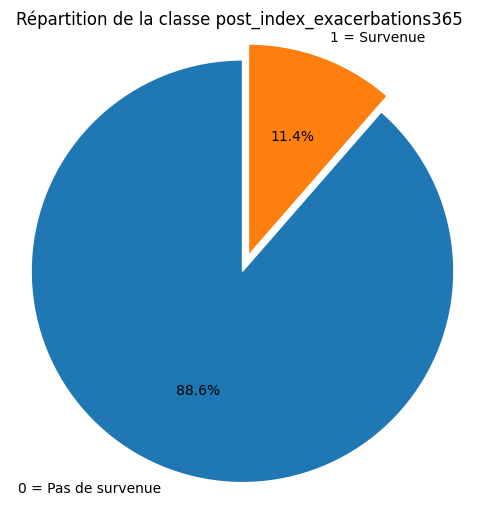

In [15]:
counts = target.value_counts().sort("post_index_exacerbations365")
labels = ["0 = Pas de survenue", "1 = Survenue"]
sizes = counts["count"].to_list()

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.02, 0.06),
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)
plt.title("Répartition de la classe post_index_exacerbations365 ")
plt.axis("equal")
plt.show()

***train tes split***

In [16]:
X_train,X_test,y_train,y_test=train_test_split(
    features,
    target,
    test_size=TEST_SIZE,
    shuffle=True,
    random_state=RANDOM_STATE,
    #stratify=target
)

X_train.shape,X_test.shape,y_train.shape,y_test.shape

((11660, 19), (2915, 19), (11660,), (2915,))

In [17]:
y_train.value_counts()

post_index_exacerbations365,count
i32,u32
1,1298
0,10362


## 3. Préprocessing

In [18]:
type(X_train)

polars.dataframe.frame.DataFrame

In [19]:
for col, dtype in X_train.schema.items():
    if dtype == pl.String:
        uniques = df.select(pl.col(col).unique()).to_series().to_list()
        print(f"{col :-<30} {uniques}")

index_age--------------------- ['37', '17', '62', '50', '13', '19', '44', '14', '59', '18', '16', '34', '54', '49', '52', '32', '25', '58', '51', '55', '47', '22', '61', '60', '30', '48', '40', '20', '31', '24', '35', '46', '12', '42', '53', '33', '27', '45', '41', '39', '56', '36', '38', 'NA', '57', '63', '26', '29', '23', '21', '43', '15', '28', '65', '64']
previous_asthma_drugs--------- ['NA', '1']
total_pre_index_cannisters_365 ['1', '2', 'NA', '0']
pneumonia--------------------- ['1', '0', 'NA']
sinusitis--------------------- ['NA', '1', '0']
acute_bronchitis-------------- ['0', '1', 'NA']
acute_laryngitis-------------- ['0', 'NA', '1']
upper_respiratory_infection--- ['1', '0', 'NA']
gerd-------------------------- ['1', 'NA', '0']
rhinitis---------------------- ['NA', '1', '0']
adherence--------------------- ['0.8501362398', '0.970027248', '0.5585831063', '0.4141689373', '0.8065395095', '0.5177111717', '0.8528610354', '0.1880108992', '0.6757493188', '0.0953678474', '0.4822888283',

In [20]:
numeric_features_int = [
 'index_age',
 'total_pre_index_cannisters_365',
 'pre_asthma_days',
]
numeric_features_float = [
 'adherence',
 'total_pre_index_charge',
 'pre_asthma_pharma_charge',
 'pre_asthma_charge',
 'log_charges',
 'log_asthma_charge',
]

categorical_features = [
 'previous_asthma_drugs',
 'pneumonia',
 'sinusitis',
 'acute_bronchitis',
 'acute_laryngitis',
 'upper_respiratory_infection',
 'gerd',
 'rhinitis',
 'drug_s',
 'female',
]

*La somme de mes catégories + entiers + floats doit être exactement égale au nombre total de colonnes.*

In [21]:
'''assert (
    len(categorical_features) +
    len(numeric_features_int) +
    len(numeric_features_float) == len(features.columns)
)'''

'assert (\n    len(categorical_features) +\n    len(numeric_features_int) +\n    len(numeric_features_float) == len(features.columns)\n)'

***Fonction de conversion de type***

In [22]:
def cast_float(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(numeric_features_float)
          .replace("NA", None)
          .cast(pl.Float64, strict=False)
    )


def cast_int(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(numeric_features_int)
          .replace("NA", None)
          .cast(pl.Int64, strict=False)
    )

def cast_categ(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(categorical_features)
          .replace("NA", None)
          .cast(pl.Int8, strict=False) # si utf8 besoin d encodage sinon non

    )

[FunctionTransformer](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.FunctionTransformer.html)

In [23]:
# construct a data transformer from a user-defined function
# input columns → output columns (mêmes noms)
cast_int_transformer = FunctionTransformer(cast_int,feature_names_out="one-to-one")
cast_float_transformer = FunctionTransformer(cast_float,feature_names_out="one-to-one")
cast_categ_transformer = FunctionTransformer(cast_categ,feature_names_out="one-to-one")

***Pipeline***

- [Pipeline , columns transformer](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html#preprocessing)
- [Imputation](https://scikit-learn.org/stable/modules/impute.html)

***Pipeline int***

In [24]:
int_pipeline = Pipeline(
    steps=[
        ("cast int",cast_int_transformer),
        ("imputer int", SimpleImputer(strategy="median")),
        #("scaler int ", RobustScaler())
        ]
)
int_pipeline

,steps,"[('cast int', ...), ('imputer int', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002C761BC07C0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Pipeline float***

In [25]:
float_pipeline = Pipeline(
    steps=[
        ("cast float",cast_float_transformer),
        ("imputer float", SimpleImputer(strategy="median")),
        #("scaler", RobustScaler())
        ]
)
float_pipeline

,steps,"[('cast float', ...), ('imputer float', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002C761BC0860>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Pipeline categ***

In [26]:
catogorical_pipeline = Pipeline(
    steps=[
        ("cast cat",cast_categ_transformer),
        ("imputer cat", SimpleImputer(strategy="most_frequent")),
        #("encode", OneHotEncoder(handle_unknown="ignore")) #Les arbres : savent gérer des variables catégorielles encodées en 0/1
        ]
)
catogorical_pipeline

,steps,"[('cast cat', ...), ('imputer cat', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cas...002C761BC0900>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


***Column tranformer***

[Columns transformer](https://scikit-learn.org/stable/modules/compose.html#column-transformer)

Applique des transformateurs aux colonnes d'un tableau ou d'un DataFrame pandas/polars. Cette méthode est particulièrement utile pour les données hétérogènes ou colonnaires, car elle permet de combiner plusieurs mécanismes d'extraction ou de transformation de caractéristiques au sein d'un seul transformateur.

Le même objet `preprocessor` est réutilisé par les trois modèles comparés : aucune différence de traitement des variables ne peut donc expliquer les écarts de performance.

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num_float', float_pipeline, numeric_features_float),
        ('num_int', int_pipeline, numeric_features_int),
        ('cat', catogorical_pipeline, categorical_features)
    ],
    #remainder="passthrough"
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_float', ...), ('num_int', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

## 4. Les trois méthodes d'ensemble

### 4.0 Apprentissage d'ensemble et compromis biais-variance

- Un modèle sous-ajusté (*underfitting*) présente généralement un biais élevé et une faible variance, tandis qu'un modèle sur-ajusté (*overfitting*) présente une variance élevée et un biais faible.

- L'apprentissage par ensembles (*ensemble learning*) consiste à combiner plusieurs modèles afin d'améliorer les performances globales. Selon la méthode utilisée, il permet de réduire la variance, le biais, ou les deux.

- Les trois méthodes comparées ici se distinguent par la manière dont elles construisent et combinent ces modèles de base, qui sont dans tous les cas des arbres de décision :

| Méthode | Entraînement des modèles de base | Effet principal | Gestion du déséquilibre |
|---|---|---|---|
| **Bagging** (`BalancedBaggingClassifier`) | indépendant, en parallèle, sur des échantillons bootstrap | réduit la **variance** | sous-échantillonnage de la classe majoritaire dans chaque échantillon |
| **Boosting** (`EasyEnsembleClassifier`) | séquentiel, chaque modèle corrige les erreurs du précédent | réduit le **biais** | un AdaBoost par échantillon bootstrap équilibré |
| **Forêt aléatoire** (`BalancedRandomForestClassifier`) | indépendant, en parallèle, avec en plus un tirage aléatoire de variables à chaque division | réduit la **variance**, en décorrélant les arbres | rééchantillonnage équilibré à chaque arbre |

- Les trois variantes retenues viennent de `imbalanced-learn` et non de `scikit-learn`, car la classe à prédire est fortement minoritaire : chacune intègre un rééquilibrage des classes au moment de la construction des modèles de base, ce qui évite d'avoir à rééchantillonner le jeu d'entraînement complet.

**Liens de référence**

- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#combining-estimators)
- [Decision tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [Ensemble methods (imbalanced-learn)](https://imbalanced-learn.org/stable/ensemble.html)

### 4.1 Bagging : `BalancedBaggingClassifier`

- **Bagging :** consiste à entraîner plusieurs modèles indépendamment et en parallèle sur différents sous-ensembles des données d'entraînement, puis à combiner leurs prédictions pour obtenir une prédiction finale. C'est différent du boosting, où l'entraînement est séquentiel et corrige les erreurs des modèles précédents.

- Permet de créer un ensemble diversifié de modèles qui capturent différents aspects des données.

- Le bagging, également appelé **agrégation par bootstrap**, se compose de deux étapes : **l'amorçage et l'agrégation**.

- **Amorçage :** des sous-échantillons bootstrap sont générés par rééchantillonnage avec remise à partir des données initiales afin d'entraîner plusieurs modèles faibles indépendants.

- **Agrégation :** les prédictions de ces modèles sont ensuite combinées, généralement par vote majoritaire ou moyenne, pour produire une prédiction finale plus stable.

- **Le bagging réduit principalement la variance du modèle en stabilisant les prédictions.**

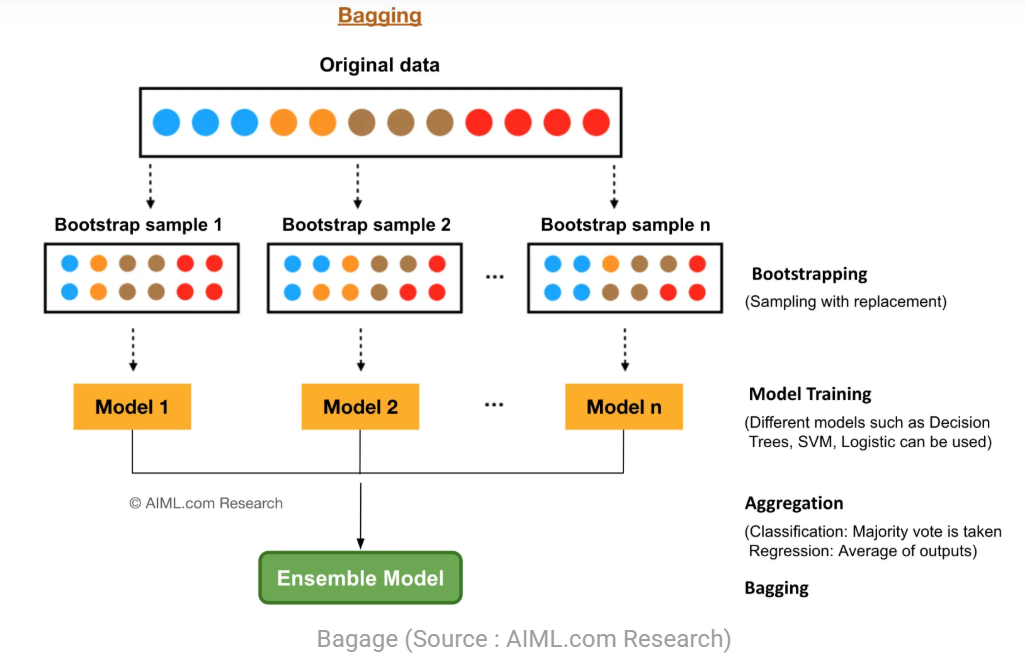

**Paramètres du classificateur Bagging :**

- `n_estimators` = nombre d'arbres. ↑ → variance ↓, modèle plus stable, temps ↑.

- `max_samples` = nombre d'échantillons tirés de X pour entraîner chaque estimateur de base. Proportion d'observations par arbre. ↓ → plus de diversité, variance ↓.

- `max_features` = nombre de caractéristiques tirées de X pour entraîner chaque estimateur de base. Proportion de variables par arbre. ↓ → arbres moins corrélés, variance ↓.

- `bootstrap` : indique si les échantillons sont tirés avec remise. Si la valeur est False, un échantillonnage sans remise est effectué.

**Structure de l'estimateur composite**

```
BalancedBaggingClassifier
 ├ Pipeline_1 → DecisionTree_1
 ├ Pipeline_2 → DecisionTree_2
 ├ Pipeline_3 → DecisionTree_3
 └ ...
```

- [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)
- [BalancedBaggingClassifier](https://imbalanced-learn.org/stable/ensemble.html#bagging-classifier)

### 4.2 Boosting : `EasyEnsembleClassifier`

- **Boosting :** méthode d'ensemble qui entraîne plusieurs modèles faibles de manière séquentielle. Chaque nouveau modèle est entraîné pour corriger les erreurs commises par les modèles précédents.

- Contrairement au bagging, où les modèles sont entraînés indépendamment et en parallèle, le boosting repose sur une dépendance entre les modèles, car chaque étape utilise l'information des erreurs précédentes.

- Le boosting construit progressivement un modèle fort en combinant plusieurs modèles faibles (*weak learners*), souvent des arbres de décision peu profonds.

- Le principe général du boosting repose sur deux idées :
    - réaccentuer les observations mal classées par les modèles précédents ;
    - ajouter successivement des modèles qui améliorent la performance globale de l'ensemble.

- Dans certains algorithmes comme AdaBoost, les observations mal classées reçoivent un poids plus élevé lors de l'apprentissage suivant. Dans les méthodes de *Gradient Boosting*, chaque nouveau modèle apprend à approximer les erreurs (résidus) du modèle précédent.

- Le boosting réduit principalement le biais du modèle, ce qui permet d'obtenir une meilleure capacité d'apprentissage, tout en maintenant une variance contrôlée grâce à la combinaison de plusieurs modèles.

> On peut imaginer une équipe d'experts qui corrigent un rapport. Le premier expert fait une première version imparfaite. Le second ne recommence pas tout, il corrige uniquement les erreurs restantes. Le troisième corrige ce que les deux premiers ont encore raté, et ainsi de suite. À la fin, le document devient beaucoup plus précis que ce qu'un seul expert aurait produit.

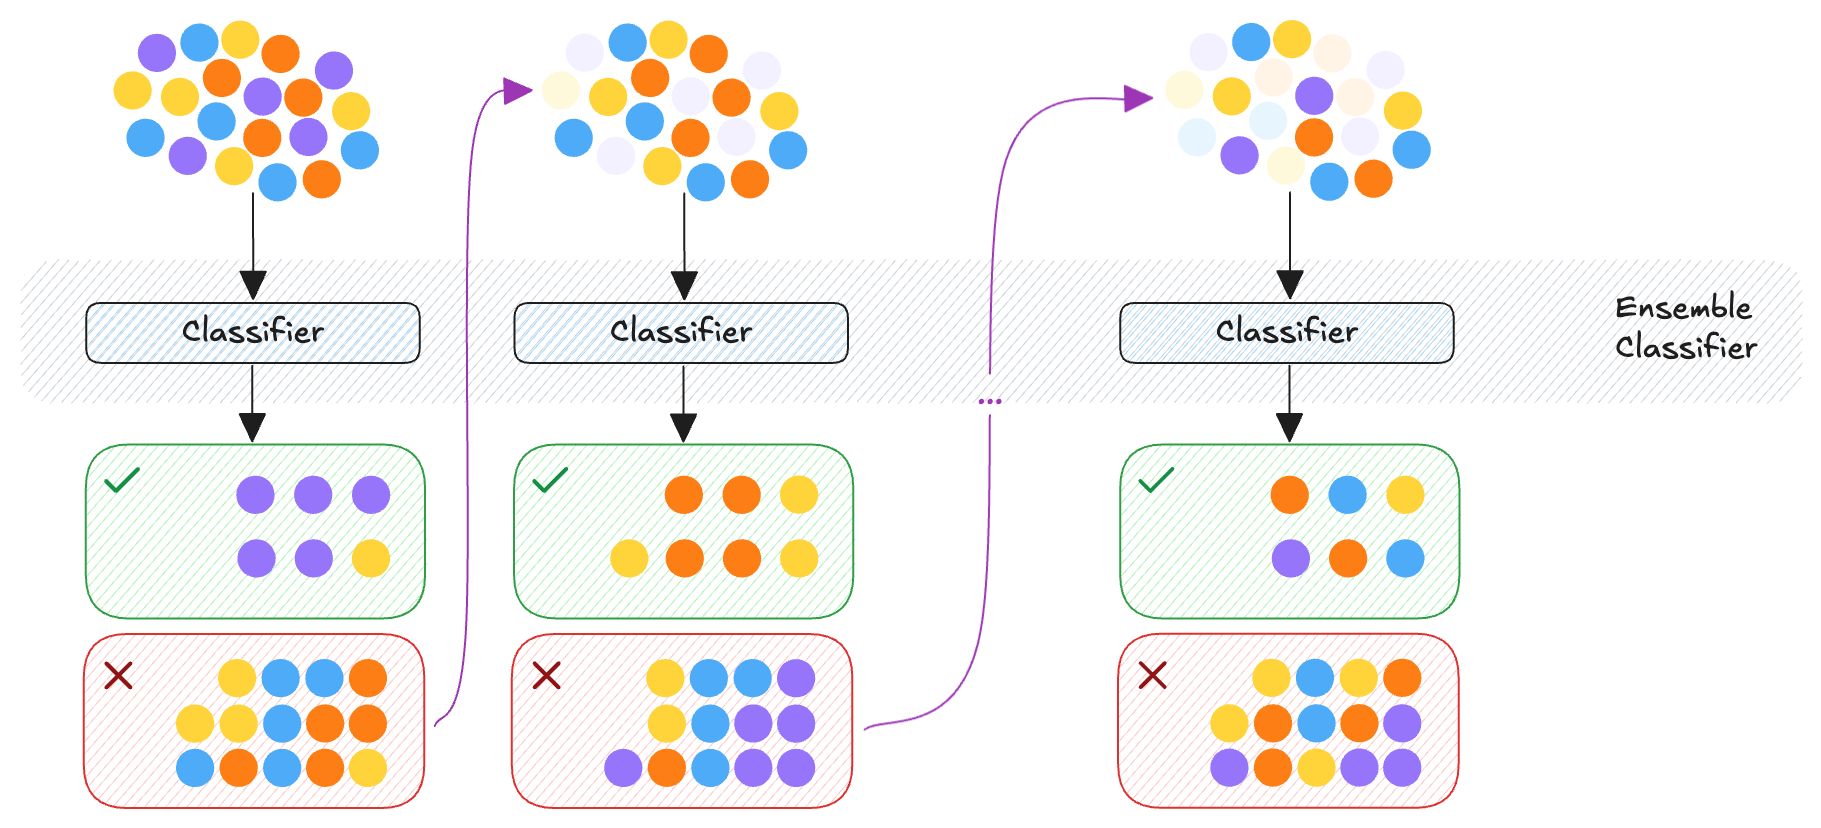

**Paramètres du boosting :**

- `n_estimators` : nombre de modèles faibles (souvent des arbres). ↑ → modèle plus expressif, biais ↓ mais risque de surapprentissage et temps d'entraînement ↑.

- `learning_rate` : poids attribué à chaque modèle ajouté dans l'ensemble. ↓ → apprentissage plus progressif et souvent plus stable, mais nécessite généralement ↑ `n_estimators`.

- `max_depth` : profondeur maximale des arbres faibles utilisés comme *base learner*. ↓ profondeur → arbres simples (*weak learners*) qui limitent le surapprentissage.

- `min_samples_leaf` : nombre minimal d'observations dans une feuille de l'arbre. ↑ valeur → arbres plus simples et meilleure généralisation.

- `subsample` (dans *Gradient Boosting*) : proportion des données utilisée pour entraîner chaque nouvel arbre. ↓ → introduit de la stochasticité, réduit la variance et limite l'overfitting.

**Structure de l'estimateur composite**

Cet algorithme est connu sous le nom d'EasyEnsemble. Le classificateur est un ensemble d'apprenants AdaBoost entraînés sur différents échantillons bootstrap équilibrés, l'équilibrage étant obtenu par sous-échantillonnage aléatoire. La structure compte donc **trois niveaux** d'imbrication :

```
EasyEnsembleClassifier
 ├ Pipeline_1 → AdaBoostClassifier_1
 │                ├ DecisionTree_1
 │                ├ DecisionTree_2
 │                └ DecisionTree_3
 ├ Pipeline_2 → AdaBoostClassifier_2
 │                └ ...
 └ Pipeline_3 → AdaBoostClassifier_3
                  └ ...
```

- [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html)
- [EasyEnsembleClassifier](https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.EasyEnsembleClassifier.html)

### 4.3 Forêt aléatoire : `BalancedRandomForestClassifier`

- *Random Forest* est une méthode de bagging appliquée aux arbres de décision, où chaque arbre est entraîné sur un sous-échantillon bootstrap des données et sur un sous-ensemble aléatoire de variables, ce qui permet de diversifier les arbres et de réduire la corrélation entre eux.

- `BalancedRandomForestClassifier` est une variante de *Random Forest* conçue pour les jeux de données déséquilibrés.

- À chaque arbre, un rééchantillonnage équilibré des classes est effectué : la classe majoritaire est sous-échantillonnée afin d'obtenir un nombre d'observations comparable à celui de la classe minoritaire.

- Chaque arbre est ensuite entraîné sur cet échantillon équilibré, ce qui permet au modèle d'accorder plus d'importance aux classes rares.

- Les prédictions des différents arbres sont ensuite agrégées (vote majoritaire) pour produire la prédiction finale.

- La forêt aléatoire équilibrée réduit principalement la variance comme le bagging classique, tout en améliorant la capacité du modèle à détecter les classes minoritaires.

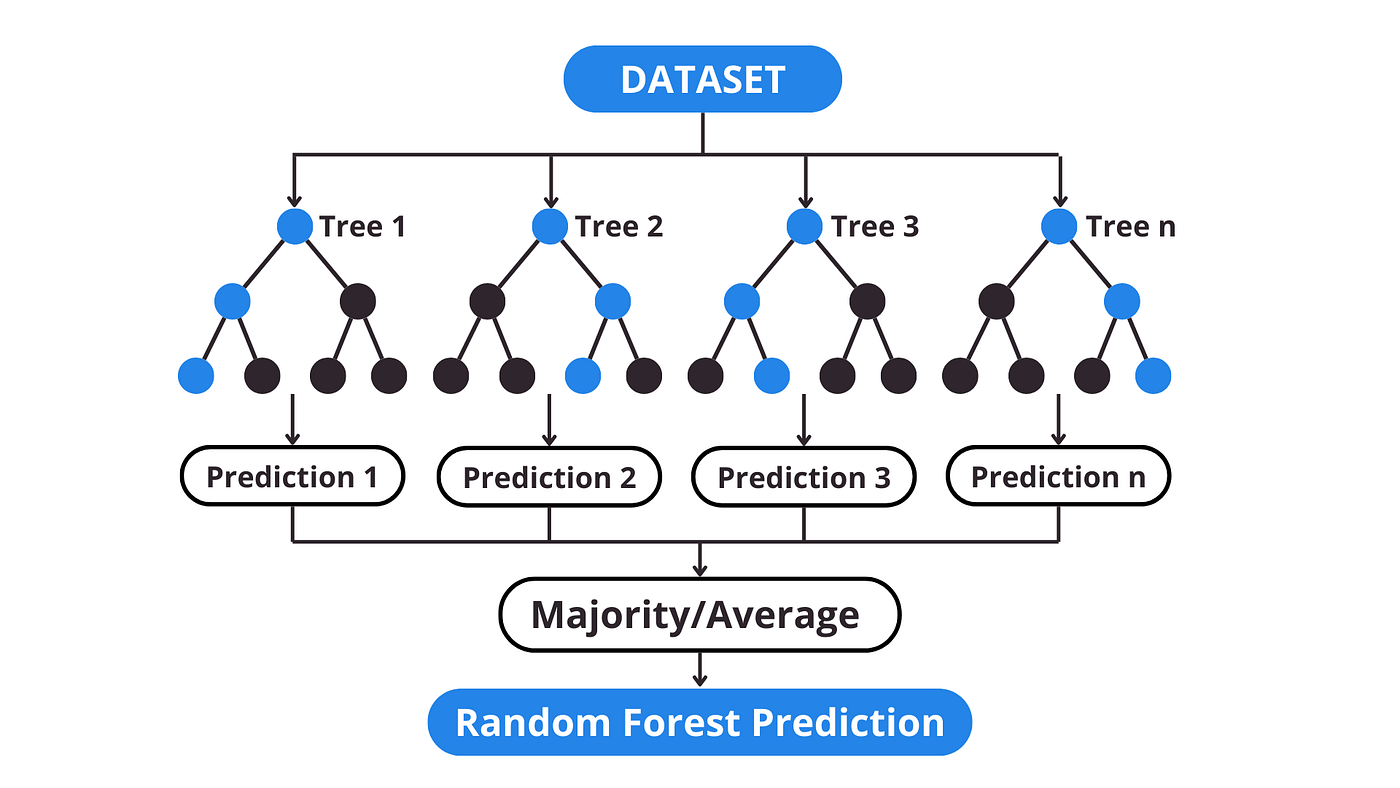

**Paramètres du classificateur Balanced Random Forest**

- `n_estimators` = nombre d'arbres dans la forêt. ↑ → variance ↓, modèle plus stable mais temps d'entraînement ↑.

- `criterion` = fonction utilisée pour mesurer la qualité d'une division. Exemples : `gini`, `entropy`.

- `max_depth` = profondeur maximale de chaque arbre. ↓ profondeur → arbres plus simples, limite le surapprentissage.

- `min_samples_split` = nombre minimal d'échantillons nécessaires pour diviser un nœud.

- `min_samples_leaf` = nombre minimal d'observations dans une feuille. ↑ valeur → modèle plus régularisé et meilleure généralisation.

- `max_features` = nombre de variables considérées à chaque division. ↓ → arbres moins corrélés → variance ↓.

- `bootstrap` = indique si les observations sont tirées avec remise lors de la construction des arbres.

**Structure de l'estimateur composite**

```
BalancedRandomForestClassifier
 ├ DecisionTree_1
 ├ DecisionTree_2
 ├ DecisionTree_3
 └ ...
```

La différence avec le bagging ci-dessus est le tirage aléatoire de variables à chaque division, qui réduit la variance du modèle tout en améliorant la détection des classes minoritaires.

- [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [BalancedRandomForestClassifier](https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedRandomForestClassifier.html)

### 4.4 Définition des trois pipelines et de leurs espaces de recherche

Chaque méthode est décrite par un *pipeline* (le préprocesseur commun, puis le modèle) et par l'espace d'hyperparamètres dans lequel la recherche bayésienne ira chercher. Les trois entrées sont rassemblées dans un dictionnaire `MODELES` : tout le reste du notebook itère sur ce dictionnaire, si bien qu'ajouter une quatrième méthode ne demanderait qu'une entrée de plus.

Les arbres ne nécessitent pas de mise à l'échelle : le préprocesseur se limite à la conversion de type et à l'imputation.

In [28]:
def construire_pipeline(modele):
    """Assemble le preprocesseur commun et un modele d ensemble."""
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),  # imputation, pas de scaling : les arbres n en ont pas besoin
            ("model", modele),
        ]
    )

In [29]:
# ---------------------------------------------------------------- BAGGING
bagging = BalancedBaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,            # [2, 3, 4, 5, 7, 10, None]
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
    ),
    n_estimators=300,           # plus on augmente le nbre d arbres, plus la variance diminue
    sampling_strategy="auto",   # ramener toutes les classes minoritaires au niveau de la classe majoritaire
    replacement=False,          # la classe majoritaire est sous-echantillonnee sans remise
    bootstrap=True,             # chaque arbre recoit un echantillon bootstrape (avec remise), reduit la variance
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
)

espace_bagging = {
    "model__n_estimators": Integer(100, 500),              # nombre d arbres
    "model__max_samples": Real(0.6, 1.0),                  # % d observations bootstrapees
    "model__estimator__max_depth": Integer(3, 20),         # profondeur des arbres
    "model__estimator__min_samples_leaf": Integer(2, 20),  # regularisation structurelle
}

# ---------------------------------------------------------------- BOOSTING
boosting = EasyEnsembleClassifier(
    estimator=AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=100,
        learning_rate=0.1,
    ),
    n_estimators=10,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

espace_boosting = {
    "model__n_estimators": Integer(5, 30),                            # nombre d AdaBoost
    "model__estimator__n_estimators": Integer(50, 200),               # nombre d arbres par AdaBoost
    "model__estimator__learning_rate": Real(0.01, 0.3, prior="log-uniform"),
    "model__estimator__estimator__max_depth": Integer(2, 6),          # profondeur des arbres faibles
}

# ---------------------------------------------------------------- FORET ALEATOIRE
foret = BalancedRandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
)

espace_foret = {
    "model__n_estimators": Integer(100, 500),
    "model__max_depth": Integer(3, 15),
    "model__min_samples_split": Integer(2, 20),
    "model__min_samples_leaf": Integer(1, 10),
    "model__max_features": Real(0.3, 1.0),   # % de variables tirees a chaque division
    "model__max_samples": Real(0.5, 1.0),    # % d observations bootstrapees
}

# ---------------------------------------------------------------- Dictionnaire d etude
MODELES = {
    "Bagging": {
        "pipeline": construire_pipeline(bagging),
        "espace": espace_bagging,
        "couleur": "tab:blue",
    },
    "Boosting": {
        "pipeline": construire_pipeline(boosting),
        "espace": espace_boosting,
        "couleur": "tab:orange",
    },
    "Foret aleatoire": {
        "pipeline": construire_pipeline(foret),
        "espace": espace_foret,
        "couleur": "tab:green",
    },
}

for nom, config in MODELES.items():
    print(f"{nom:<18} {type(config['pipeline'].named_steps['model']).__name__}")

Bagging            BalancedBaggingClassifier
Boosting           EasyEnsembleClassifier
Foret aleatoire    BalancedRandomForestClassifier


In [30]:
# Apercu du pipeline : identique pour les trois, au modele final pres
MODELES["Bagging"]["pipeline"]

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_float', ...), ('num_int', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for forma

## 5. Protocole d'évaluation commun

***Stratégie générale*** (appliquée à l'identique aux trois modèles)

- → Training data (sans optimisation)
- → Cross-validation (hyperparam tuning)
- → Best parameters
- → Retrained model (avec optimisation des paramètres)
- → Threshold optimization (CV sur training)
- → Final evaluation (sur test)

Le jeu de test n'intervient qu'à la dernière étape : il ne sert ni au choix des hyperparamètres, ni au choix du seuil, ni au choix de la méthode retenue.

[F1 Score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

Dans `classification_report`, on a :

- F1 classe 0 : c'est la performance du modèle pour détecter correctement les 0.
- F1 classe 1 : c'est la performance du modèle pour détecter correctement les 1.
- F1 macro : c'est la moyenne simple, chaque classe compte autant (voir si le modèle est équilibré).
- F1 weighted : c'est la moyenne pondérée par le nombre d'exemples (si la classe 0 représente 85 % des données, le *weighted* sera fortement influencé par elle).

Objectif = bien classer les cas 1 minoritaires = F1 classe 1

- La précision évalue la fiabilité des prédictions positives : proportion réellement positive, parmi les observations prédites comme positives.
- Le rappel évalue la capacité du modèle à détecter les cas réels : proportion correctement détectée, parmi les observations réellement positives.

### 5.1 Accès aux arbres, quelle que soit la méthode

C'est le seul endroit où les trois méthodes demandent un traitement particulier : les arbres de décision ne sont pas rangés à la même profondeur selon l'ensemble considéré. La forêt aléatoire expose directement ses arbres, le bagging les enveloppe dans un *pipeline* interne, et EasyEnsemble ajoute un niveau AdaBoost.

Plutôt que d'écrire trois extractions, une fonction récursive descend dans la structure jusqu'à rencontrer des arbres : elle traverse les *pipelines* par leur dernière étape et les ensembles par leurs sous-estimateurs. Le même code sert donc pour les trois méthodes, et pour toute méthode d'ensemble à base d'arbres qu'on ajouterait ensuite.

In [31]:
def extraire_arbres(estimateur):
    """Retourne la liste des arbres de decision contenus dans un estimateur,
    quelle que soit la profondeur d imbrication.

    - DecisionTreeClassifier          -> [lui-meme]
    - Pipeline                        -> descend dans sa derniere etape
    - ensemble (attribut estimators_) -> concatene les sous-estimateurs
    """
    if hasattr(estimateur, "tree_"):                 # un arbre ajuste
        return [estimateur]

    if hasattr(estimateur, "steps"):                 # un Pipeline interne
        return extraire_arbres(estimateur.steps[-1][1])

    if hasattr(estimateur, "estimators_"):           # un ensemble
        arbres = []
        for sous_estimateur in estimateur.estimators_:
            arbres.extend(extraire_arbres(sous_estimateur))
        return arbres

    return []


def importances_gini(modele, noms_variables):
    """Moyenne des importances (reduction d impurete de Gini) sur tous les arbres."""
    arbres = extraire_arbres(modele)
    cumul = np.zeros(len(noms_variables))

    for arbre in arbres:
        cumul += arbre.feature_importances_

    return pd.Series(cumul / len(arbres), index=noms_variables), len(arbres)

### 5.2 Les étapes du protocole

Chaque étape est une fonction qui prend le modèle courant et renvoie ce qui sera comparé ensuite. Les variables globales `X_train`, `y_train`, `X_test` et `y_test` ne sont jamais réassignées à l'intérieur de ces fonctions : les trois modèles voient donc rigoureusement les mêmes données.

***Entraînement sans optimisation***

Les prédictions sont calculées hors échantillon (*out-of-fold*) par validation croisée sur le jeu d'entraînement : chaque observation est prédite par un modèle qui ne l'a pas vue.

In [32]:
# Cross-validation stratifiee
# StratifiedKFold : garde la meme proportion de classe 1 dans chaque fold.
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


def etape_baseline(nom, pipe):
    """Predictions out-of-fold du modele non optimise."""
    y_pred = cross_val_predict(pipe, X_train, y_train, cv=cv, n_jobs=N_JOBS)
    y_proba = cross_val_predict(
        pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=N_JOBS
    )[:, 1]

    f1 = f1_score(y_train, y_pred)
    auc = roc_auc_score(y_train, y_proba)

    print(f"[{nom}] Baseline CV F1      : {f1:.4f}")
    print(f"[{nom}] Baseline CV ROC-AUC : {auc:.4f}")
    print(f"[{nom}] Probabilite maximale predite : {y_proba.max():.4f}")
    print(classification_report(y_train, y_pred))

    # score moyen par classe reelle : un ecart faible signale une separation faible
    print(
        pd.DataFrame({"y": np.asarray(y_train), "score": y_proba})
        .groupby("y")
        .mean()
    )

    return {"y_pred_cv": y_pred, "y_proba_cv": y_proba, "f1_cv": f1, "auc_cv": auc}

***Matrice de confusion et courbe ROC***

**Est-ce que mon modèle sait séparer les classes, indépendamment du seuil ?**

La courbe ROC est une courbe qui montre la capacité d'un modèle à distinguer les classes en traçant le taux de vrais positifs contre le taux de faux positifs pour tous les seuils possibles.

- FPR (*False Positive Rate*) : proportion de négatifs mal classés
- TPR (*True Positive Rate*) : proportion de positifs bien détectés
- Montre comment évolue le compromis sensibilité / faux positifs

L'AUC (aire sous la courbe ROC) mesure la capacité globale du modèle à séparer les classes indépendamment du seuil : plus elle est proche de 1, meilleure est la discrimination.

La distribution des probabilités permet d'évaluer visuellement cette séparabilité. Le seuil de décision transforme ces probabilités en classes prédites, et son ajustement contrôle le compromis précision-rappel. Le seuil peut être optimisé en fonction de l'objectif clinique (dépistage sensible ou prédiction plus spécifique).

In [33]:
def tracer_diagnostic_cv(nom, y_pred, y_proba, couleur):
    """Matrice de confusion, courbe ROC et distribution des probabilites (CV sur train)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    # ---- Matrice de confusion
    cm = confusion_matrix(y_train, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    axes[0].set_title(f"{nom} : matrice de confusion (CV - Train)")

    # ---- Courbe ROC
    fpr, tpr, _ = roc_curve(y_train, y_proba)
    auc = roc_auc_score(y_train, y_proba)

    axes[1].plot(fpr, tpr, linewidth=2, color=couleur, label=f"AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].fill_between(fpr, tpr, alpha=0.2, color=couleur)
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{nom} : courbe ROC (CV - Train)")
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)

    # ---- Distribution des probabilites
    cible = np.asarray(y_train)
    axes[2].hist(y_proba[cible == 0], bins=50, alpha=0.5, label="Classe 0")
    axes[2].hist(y_proba[cible == 1], bins=50, alpha=0.5, label="Classe 1")
    axes[2].legend()
    axes[2].set_xlabel("Probabilite predite")
    axes[2].set_title(f"{nom} : distribution des probabilites (CV - Train)")

    plt.tight_layout()
    plt.show()

***Courbe d'apprentissage (learning curve)***

**Le modèle manque-t-il de données ? Ou manque-t-il d'information ?**

- Si Train >> Val → overfitting, davantage de données aideraient. Le bagging fait baisser la variance, donc réduit l'overfitting.
- Si les deux sont bas et se rejoignent → underfitting (biais), le modèle est limité par la structure des données.
- Si Val monte encore → manque de données.

In [34]:
def etape_courbe_apprentissage(nom, pipe, couleur):
    """Courbe d apprentissage du modele non optimise."""
    tailles, scores_train, scores_val = learning_curve(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=N_JOBS,
        train_sizes=np.linspace(0.1, 1.0, 5),
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(tailles, scores_train.mean(axis=1), marker="o",
             color=couleur, label="Train")
    plt.plot(tailles, scores_val.mean(axis=1), marker="s", linestyle="--",
             color=couleur, alpha=0.6, label="Validation")
    plt.legend()
    plt.xlabel("Training size")
    plt.ylabel(f"Score {SCORING}")
    plt.title(f"{nom} : courbe d apprentissage (baseline)")
    plt.grid(alpha=0.3)
    plt.show()

    return {
        "tailles": tailles,
        "scores_train": scores_train.mean(axis=1),
        "scores_val": scores_val.mean(axis=1),
    }

***Réglage des hyperparamètres***

[Validation croisée, optimisation des hyperparamètres, seuil de décision, métriques de prédiction, courbe de validation](https://scikit-learn.org/stable/model_selection.html)

Les hyperparamètres sont des paramètres qui ne sont pas directement appris par les estimateurs. Dans scikit-learn, ils sont passés comme arguments au constructeur des classes d'estimateurs.

- Pourquoi optimiser les hyperparamètres ? = impact majeur sur les performances
- Le bon réglage peut gagner 10 à 15 % de performance.

***Stratégie de recherche du meilleur hyperparamètre***

- choisir un estimateur (régresseur ou classificateur) ;
- définir un espace de paramètres ;
- choisir une méthode de recherche ou d'échantillonnage de candidats : [recherche bayésienne](https://www.nextstruggle.com/bayesian-optimization-for-hyperparameter-tuning-in-python-scikit-learn/askdushyant/) ;
- un schéma de validation croisée ;
- une fonction de score.

Pour chaque combinaison d'hyperparamètres, la recherche entraîne le modèle sur les *folds*, l'évalue, calcule la moyenne en validation croisée, compare les scores et garde le meilleur. Les trois modèles reçoivent le même nombre d'itérations, le même critère d'arrêt et le même découpage.

In [35]:
def etape_tuning(nom, pipe, espace):
    """Recherche bayesienne des hyperparametres, puis reentrainement sur tout X_train."""
    recherche = BayesSearchCV(
        estimator=pipe,
        search_spaces=espace,
        n_iter=N_ITER,
        scoring=SCORING,
        cv=cv,
        refit=True,       # une fois le meilleur jeu trouve, reentraine sur tout X_train
        n_jobs=N_JOBS,
        verbose=0,
        random_state=RANDOM_STATE,
    )

    recherche.fit(
        X_train,
        y_train,
        callback=[
            DeltaYStopper(delta=0.001)  # arret si l amelioration reste sous 0.001
        ],
    )

    print(f"[{nom}] Best CV {SCORING} : {recherche.best_score_:.4f}")
    print(f"[{nom}] Best parameters :")
    for cle, valeur in recherche.best_params_.items():
        print(f"    {cle:<45} {valeur}")

    return {
        "best_model": recherche.best_estimator_,
        "best_params": dict(recherche.best_params_),
        "f1_cv_tuned": recherche.best_score_,
    }

***Visualisation d'un arbre et importance des variables***

L'indice de Gini est une mesure du degré de mélange des classes dans un nœud d'un arbre de décision.

- Si un nœud contient uniquement une seule classe → Gini = 0 (pur)
- Si les classes sont parfaitement équilibrées → Gini maximal (impur)

À chaque division, l'arbre cherche la variable qui sépare les données en diminuant le Gini le plus possible, autrement dit qui crée des sous-groupes aussi purs que possible.

La *permutation importance* mesure de combien la performance baisse quand on casse le lien entre une variable et la cible, en permutant ses valeurs. Contrairement à l'importance de Gini, elle ne favorise pas mécaniquement les variables à nombreuses modalités.

In [36]:
def etape_importances(nom, best_model, couleur):
    """Arbre individuel, importances de Gini moyennes et importances par permutation."""
    noms_variables = best_model.named_steps["preprocessor"].get_feature_names_out()
    modele = best_model.named_steps["model"]

    # ---- un arbre individuel de l ensemble
    arbres = extraire_arbres(modele)

    plt.figure(figsize=(24, 10))
    plot_tree(
        arbres[0],
        feature_names=noms_variables,
        filled=True,
        max_depth=3,
        fontsize=11,
        rounded=True,
    )
    plt.title(f"{nom} : premier arbre de l ensemble ({len(arbres)} arbres au total)",
              fontsize=15)
    plt.show()

    # ---- importances de Gini, moyennees sur tous les arbres
    gini, n_arbres = importances_gini(modele, noms_variables)

    # ---- importances par permutation, sur les donnees pretraitees
    X_transforme = best_model.named_steps["preprocessor"].transform(X_train)
    permutation = permutation_importance(
        modele,
        X_transforme,
        y_train,
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )
    perm = pd.Series(permutation.importances_mean, index=noms_variables)

    # ---- affichage cote a cote
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    gini.sort_values().tail(10).plot(kind="barh", ax=axes[0], color=couleur)
    axes[0].set_title(f"{nom} : top 10 importances de Gini ({n_arbres} arbres)")
    axes[0].set_xlabel("Importance")

    perm.sort_values().tail(10).plot(kind="barh", ax=axes[1], color=couleur)
    axes[1].set_title(f"{nom} : top 10 importances par permutation")
    axes[1].set_xlabel("Importance")

    plt.tight_layout()
    plt.show()

    return {
        "noms_variables": noms_variables,
        "importances_gini": gini,
        "importances_permutation": perm,
        "n_arbres": n_arbres,
    }

***Réglage du seuil (threshold tuning)***

Le seuil est la frontière de décision qui transforme une probabilité continue en classe binaire. Voir [cette présentation du seuil](https://developers.google.com/machine-learning/crash-course/classification/thresholding?hl=fr).

- Le modèle optimisé est entraîné en validation croisée sur le jeu d'entraînement.
- Pour chaque *fold*, les probabilités sont calculées.
- Le seuil optimal est choisi pour maximiser le F1.
- Ensuite, le modèle est réentraîné automatiquement sur tout le jeu d'entraînement.
- Le seuil optimal est stocké dans `best_threshold_`.

Si on baisse le seuil : plus de patients sont classés à risque, les faux négatifs diminuent, les faux positifs augmentent, le rappel monte et la précision baisse. Si on augmente le seuil, l'effet est inverse : on rate plus de vrais cas mais on produit moins de fausses alertes.

In [37]:
def etape_seuil(nom, best_model, couleur):
    """Reglage du seuil de decision par validation croisee sur le train."""
    tuner = TunedThresholdClassifierCV(
        estimator=best_model,
        scoring=SCORING,
        cv=cv,
        n_jobs=N_JOBS,
    ).fit(X_train, y_train)

    seuil = tuner.best_threshold_
    print(f"[{nom}] Seuil optimal (CV)        : {seuil:.4f}")
    print(f"[{nom}] CV {SCORING} apres reglage du seuil : {tuner.best_score_:.4f}")

    # ---- distribution des probabilites sur le train, avec VN / FP / FN / VP
    proba_train = tuner.predict_proba(X_train)[:, 1]
    pred_train = np.asarray(tuner.predict(X_train))
    cible = np.asarray(y_train)

    masques = {
        "VN": (cible == 0) & (pred_train == 0),
        "FP": (cible == 0) & (pred_train == 1),
        "FN": (cible == 1) & (pred_train == 0),
        "VP": (cible == 1) & (pred_train == 1),
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    sns.kdeplot(proba_train[cible == 0], ax=axes[0], fill=True, alpha=0.3,
                label="Pas de survenue d exacerbation (reel)")
    sns.kdeplot(proba_train[cible == 1], ax=axes[0], fill=True, alpha=0.3,
                label="Survenue d exacerbation (reel)")

    for etiquette, masque in masques.items():
        axes[0].scatter(proba_train[masque], np.zeros(masque.sum()),
                        alpha=0.4, label=etiquette)

    axes[0].axvline(seuil, linestyle="--", color="black",
                    label=f"Seuil = {seuil:.3f}")
    axes[0].set_xlabel("Probabilite predite")
    axes[0].set_ylabel("Densite")
    axes[0].set_title(f"{nom} : probabilites (Train) et VN/FP/FN/VP")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    cm = confusion_matrix(cible, pred_train)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
    axes[1].set_xlabel("Predit")
    axes[1].set_ylabel("Reel")
    axes[1].set_title(f"{nom} : matrice de confusion (Train, seuil = {seuil:.3f})")

    plt.tight_layout()
    plt.show()

    return {
        "threshold_tuner": tuner,
        "seuil": seuil,
        "f1_cv_seuil": tuner.best_score_,
    }

***Évaluation finale sur le jeu de test***

C'est la seule étape qui utilise `X_test`. Elle est faite une fois par modèle, après que les hyperparamètres et le seuil ont été fixés sur le seul jeu d'entraînement.

Si la probabilité prédite est supérieure ou égale au seuil, le patient est classé 1 (survenue d'exacerbation), sinon 0 (pas d'exacerbation).

In [38]:
def etape_test(nom, tuner):
    """Evaluation finale sur le jeu de test, seuil regle inclus."""
    y_pred = tuner.predict(X_test)
    y_proba = tuner.predict_proba(X_test)[:, 1]

    scores = {
        "f1_test": f1_score(y_test, y_pred),
        "precision_test": precision_score(y_test, y_pred, zero_division=0),
        "recall_test": recall_score(y_test, y_pred),
        "auc_test": roc_auc_score(y_test, y_proba),
    }

    print(f"[{nom}] TEST F1        : {scores['f1_test']:.4f}")
    print(f"[{nom}] TEST precision : {scores['precision_test']:.4f}")
    print(f"[{nom}] TEST rappel    : {scores['recall_test']:.4f}")
    print(f"[{nom}] TEST ROC-AUC   : {scores['auc_test']:.4f}")
    print(classification_report(y_test, y_pred))

    return {"y_pred_test": y_pred, "y_proba_test": y_proba, **scores}

### 5.3 Enchaînement complet

`evaluer_modele` appelle les étapes dans l'ordre et rassemble tout ce qui servira à la comparaison. Le temps de calcul est mesuré pour chaque méthode : il fait partie de la comparaison, une méthode légèrement meilleure mais dix fois plus lente n'étant pas forcément celle à retenir.

In [39]:
def evaluer_modele(nom, config):
    """Applique le protocole complet a une methode et renvoie tous ses resultats."""
    print("=" * 90)
    print(f"  {nom}")
    print("=" * 90)

    depart = time.perf_counter()
    pipe = config["pipeline"]
    couleur = config["couleur"]
    resultat = {"nom": nom, "couleur": couleur, "pipeline": pipe}

    # 1. baseline hors echantillon
    print(f"\n--- [{nom}] 1. baseline (validation croisee, sans optimisation)")
    baseline = etape_baseline(nom, pipe)
    resultat.update(baseline)
    tracer_diagnostic_cv(nom, baseline["y_pred_cv"], baseline["y_proba_cv"], couleur)

    # 2. courbe d apprentissage
    print(f"\n--- [{nom}] 2. courbe d apprentissage")
    resultat["courbe_apprentissage"] = etape_courbe_apprentissage(nom, pipe, couleur)

    # 3. reglage des hyperparametres
    print(f"\n--- [{nom}] 3. recherche bayesienne ({N_ITER} iterations)")
    tuning = etape_tuning(nom, pipe, config["espace"])
    resultat.update(tuning)

    # 4. arbres et importances
    print(f"\n--- [{nom}] 4. arbre individuel et importance des variables")
    resultat.update(etape_importances(nom, tuning["best_model"], couleur))

    # 5. reglage du seuil
    print(f"\n--- [{nom}] 5. reglage du seuil de decision")
    seuil = etape_seuil(nom, tuning["best_model"], couleur)
    resultat.update(seuil)

    # 6. evaluation finale
    print(f"\n--- [{nom}] 6. evaluation sur le jeu de test")
    resultat.update(etape_test(nom, seuil["threshold_tuner"]))

    resultat["duree_s"] = time.perf_counter() - depart
    print(f"\n[{nom}] Duree totale : {resultat['duree_s'] / 60:.1f} min\n")

    return resultat

## 6. Exécution sur les trois modèles

La cellule suivante enchaîne le protocole complet sur les trois méthodes. Avec `N_ITER = 80`, chaque méthode demande une recherche bayésienne de 80 itérations en validation croisée à 5 *folds*, plus les courbes d'apprentissage et le réglage du seuil : prévoir un temps de calcul long, en particulier pour le boosting dont chaque candidat entraîne plusieurs AdaBoost.

Les résultats sont conservés dans le dictionnaire `RESULTATS`, qu'exploite la section suivante.

  Bagging

--- [Bagging] 1. baseline (validation croisee, sans optimisation)
[Bagging] Baseline CV F1      : 0.2168
[Bagging] Baseline CV ROC-AUC : 0.5732
[Bagging] Probabilite maximale predite : 0.6741
              precision    recall  f1-score   support

           0       0.91      0.51      0.65     10362
           1       0.13      0.60      0.22      1298

    accuracy                           0.52     11660
   macro avg       0.52      0.55      0.43     11660
weighted avg       0.82      0.52      0.60     11660

      score
y          
0  0.487588
1  0.503034


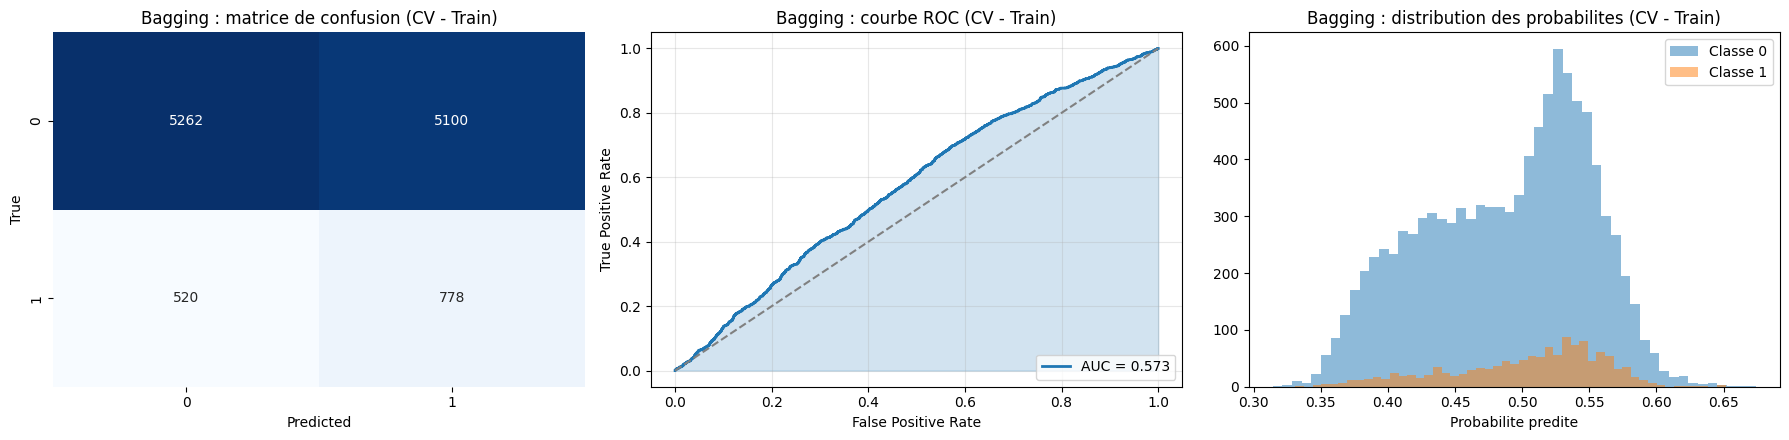


--- [Bagging] 2. courbe d apprentissage


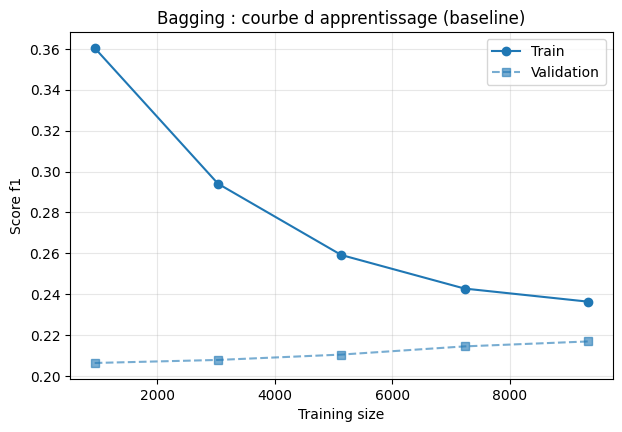


--- [Bagging] 3. recherche bayesienne (80 iterations)
[Bagging] Best CV f1 : 0.2230
[Bagging] Best parameters :
    model__estimator__max_depth                   3
    model__estimator__min_samples_leaf            11
    model__max_samples                            0.6471258997869709
    model__n_estimators                           100

--- [Bagging] 4. arbre individuel et importance des variables


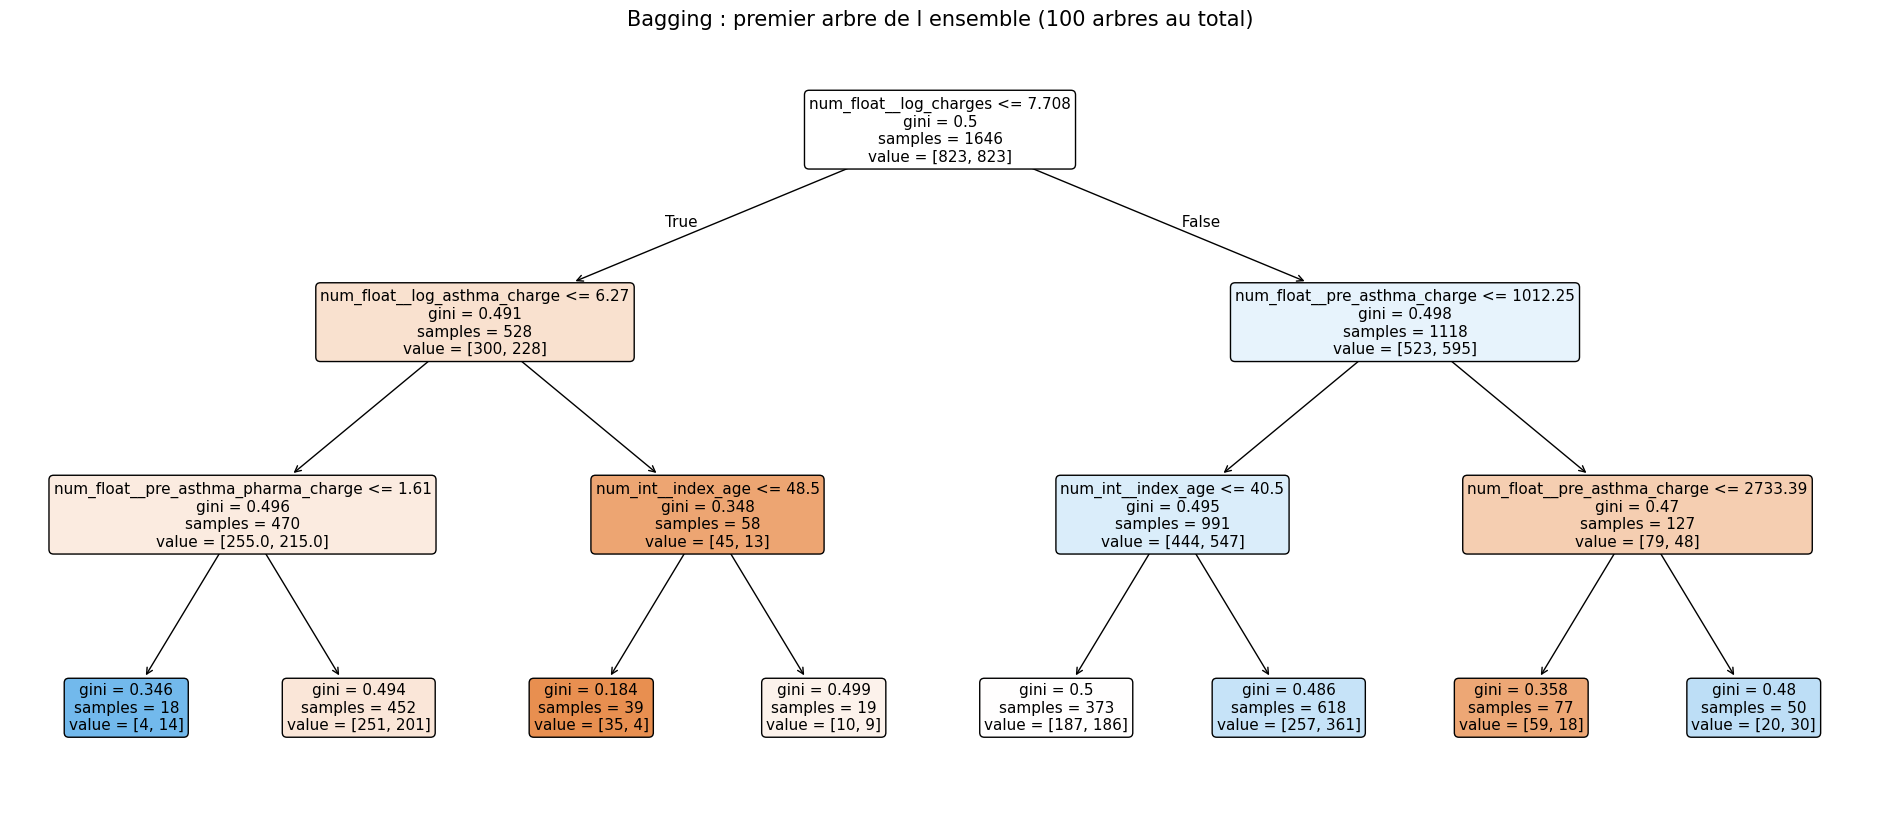

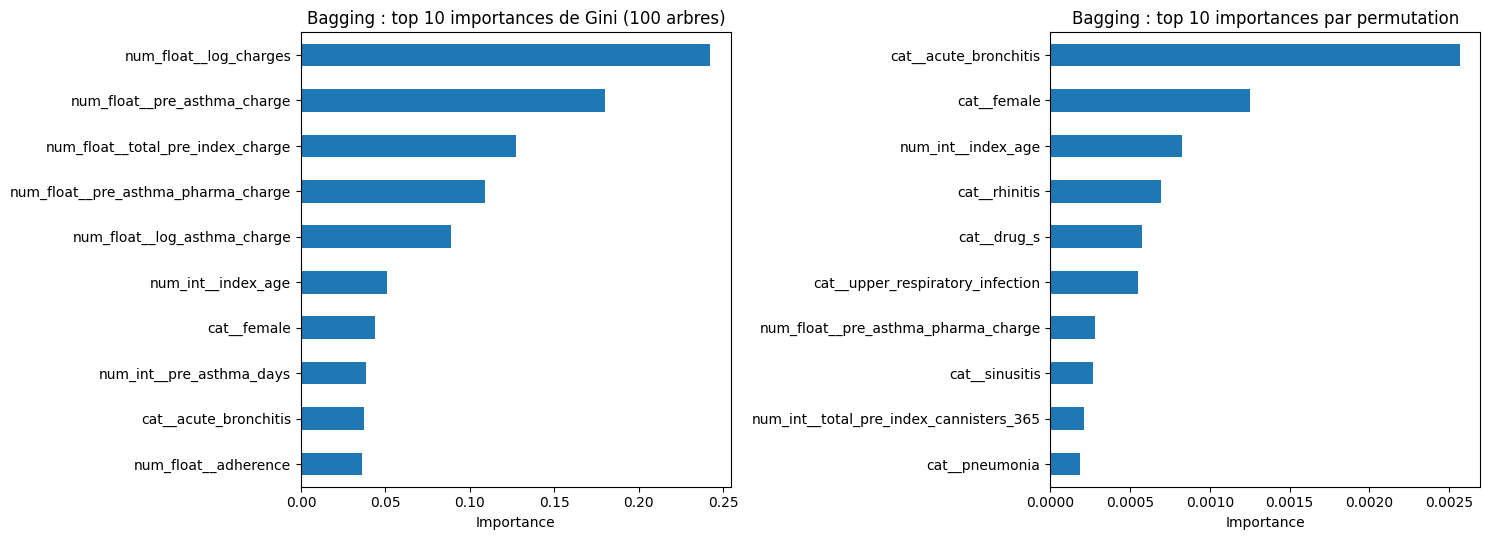


--- [Bagging] 5. reglage du seuil de decision
[Bagging] Seuil optimal (CV)        : 0.4984
[Bagging] CV f1 apres reglage du seuil : 0.2221


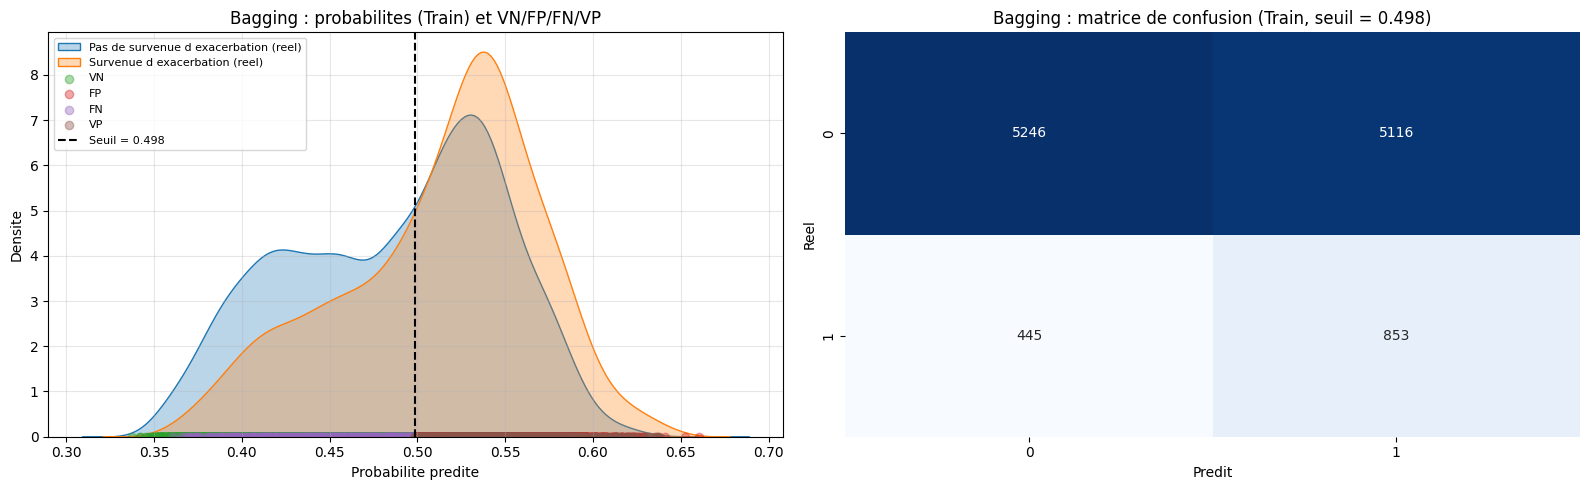


--- [Bagging] 6. evaluation sur le jeu de test
[Bagging] TEST F1        : 0.2364
[Bagging] TEST precision : 0.1466
[Bagging] TEST rappel    : 0.6099
[Bagging] TEST ROC-AUC   : 0.5592
              precision    recall  f1-score   support

           0       0.90      0.49      0.64      2551
           1       0.15      0.61      0.24       364

    accuracy                           0.51      2915
   macro avg       0.52      0.55      0.44      2915
weighted avg       0.80      0.51      0.59      2915


[Bagging] Duree totale : 24.5 min

  Boosting

--- [Boosting] 1. baseline (validation croisee, sans optimisation)
[Boosting] Baseline CV F1      : 0.2158
[Boosting] Baseline CV ROC-AUC : 0.5730
[Boosting] Probabilite maximale predite : 0.8183
              precision    recall  f1-score   support

           0       0.91      0.55      0.68     10362
           1       0.13      0.56      0.22      1298

    accuracy                           0.55     11660
   macro avg       0.52    

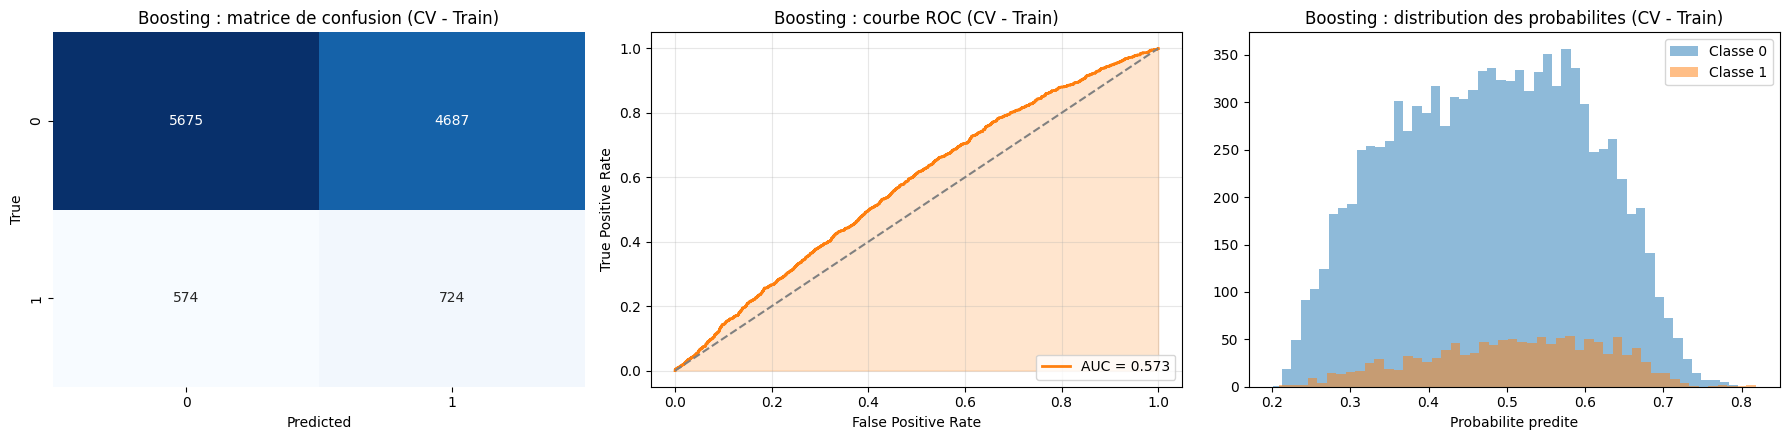


--- [Boosting] 2. courbe d apprentissage


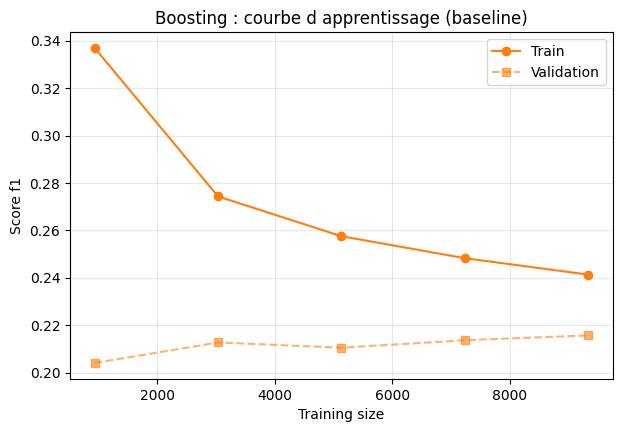


--- [Boosting] 3. recherche bayesienne (80 iterations)
[Boosting] Best CV f1 : 0.2217
[Boosting] Best parameters :
    model__estimator__estimator__max_depth        6
    model__estimator__learning_rate               0.01
    model__estimator__n_estimators                199
    model__n_estimators                           30

--- [Boosting] 4. arbre individuel et importance des variables


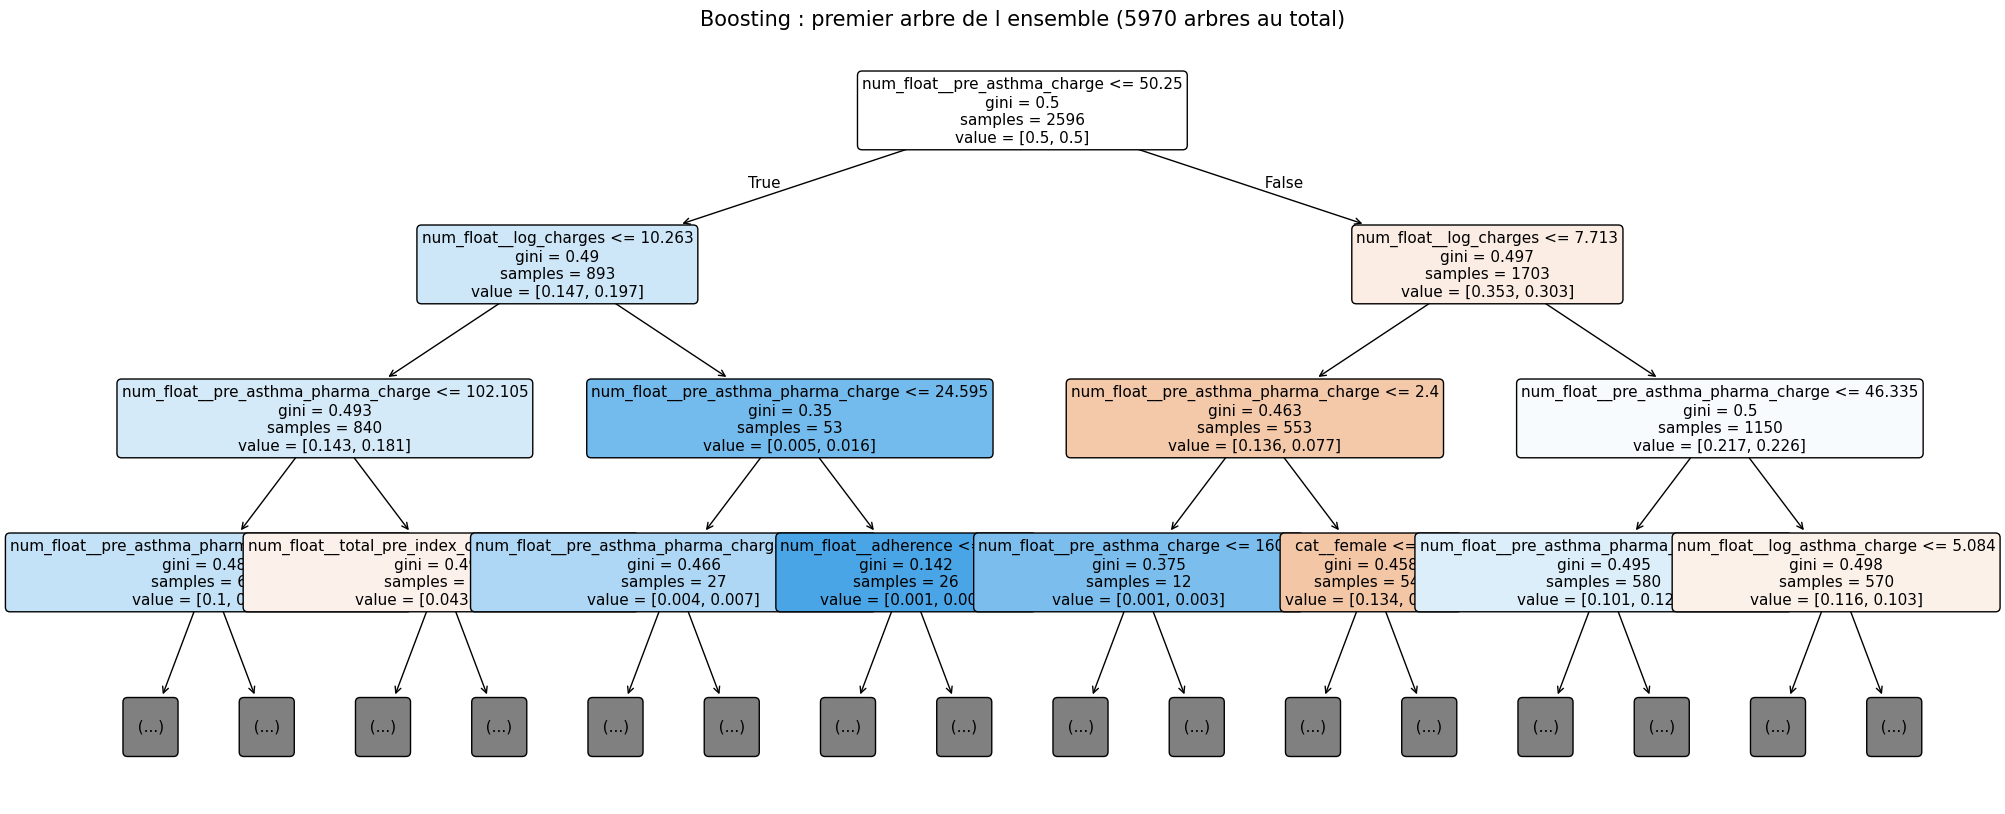

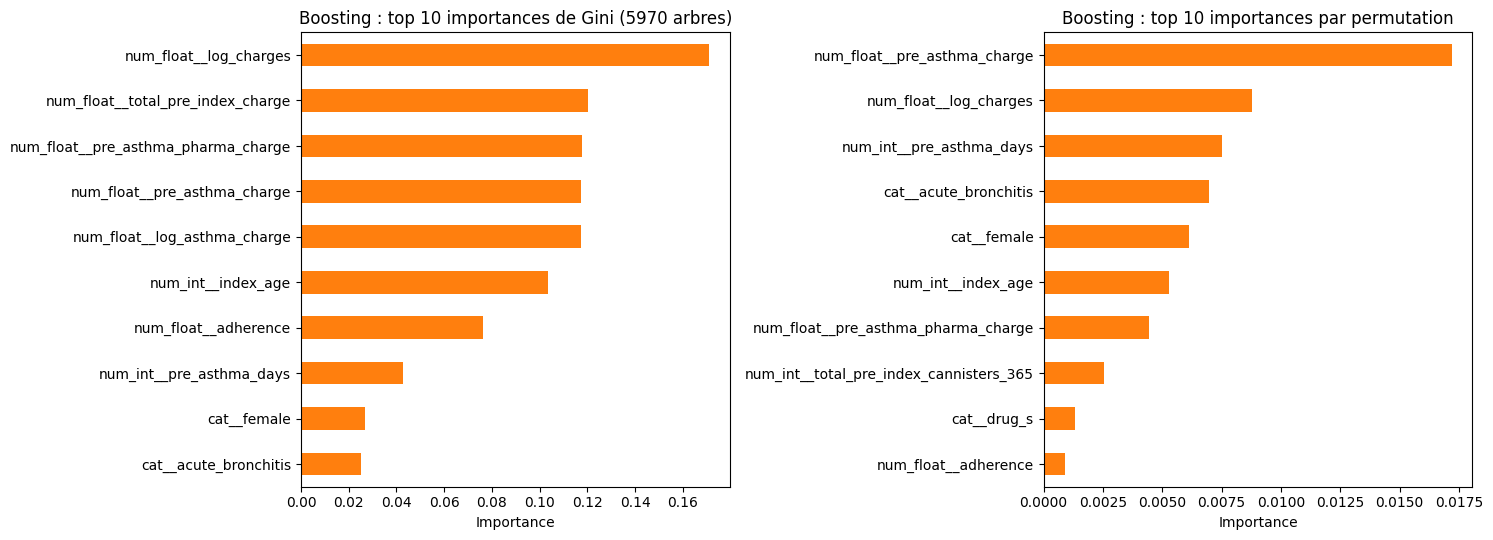


--- [Boosting] 5. reglage du seuil de decision
[Boosting] Seuil optimal (CV)        : 0.4940
[Boosting] CV f1 apres reglage du seuil : 0.2210


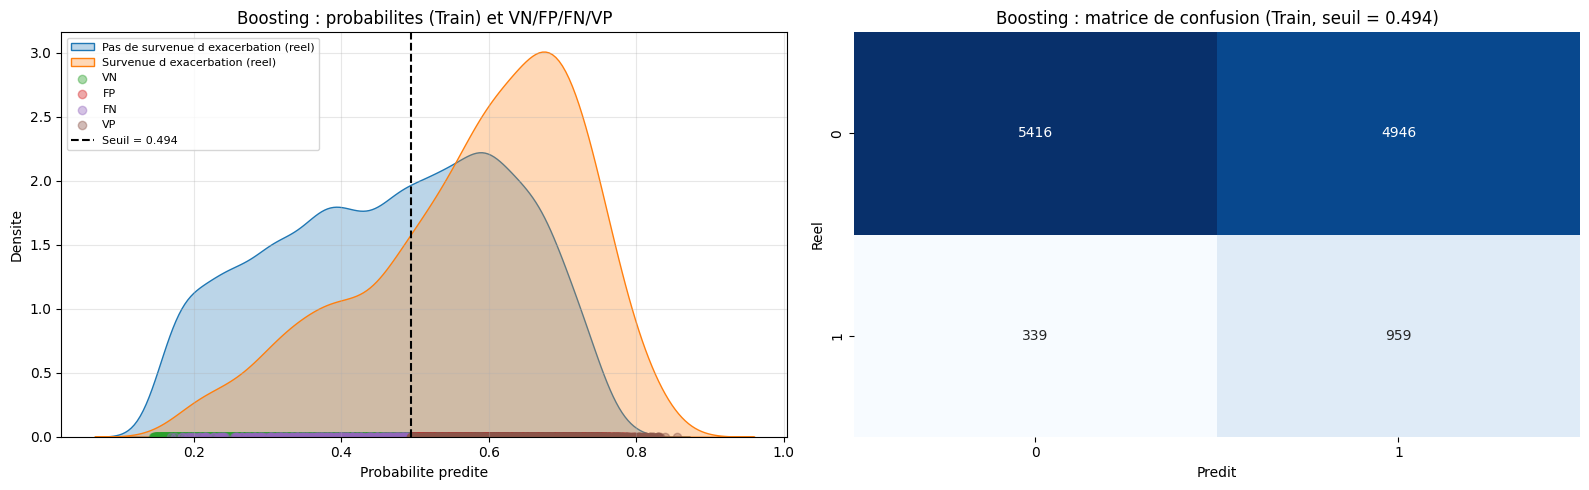


--- [Boosting] 6. evaluation sur le jeu de test
[Boosting] TEST F1        : 0.2383
[Boosting] TEST precision : 0.1481
[Boosting] TEST rappel    : 0.6099
[Boosting] TEST ROC-AUC   : 0.5622
              precision    recall  f1-score   support

           0       0.90      0.50      0.64      2551
           1       0.15      0.61      0.24       364

    accuracy                           0.51      2915
   macro avg       0.52      0.55      0.44      2915
weighted avg       0.81      0.51      0.59      2915


[Boosting] Duree totale : 86.5 min

  Foret aleatoire

--- [Foret aleatoire] 1. baseline (validation croisee, sans optimisation)
[Foret aleatoire] Baseline CV F1      : 0.2175
[Foret aleatoire] Baseline CV ROC-AUC : 0.5760
[Foret aleatoire] Probabilite maximale predite : 0.6334
              precision    recall  f1-score   support

           0       0.91      0.55      0.69     10362
           1       0.14      0.56      0.22      1298

    accuracy                           0

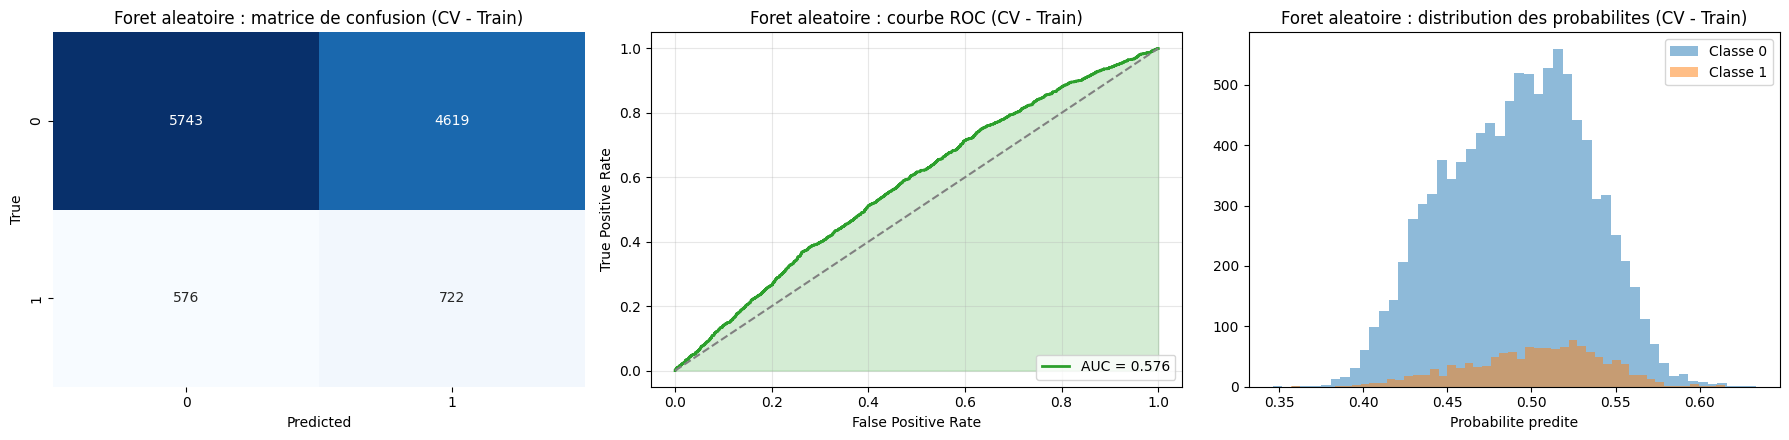


--- [Foret aleatoire] 2. courbe d apprentissage


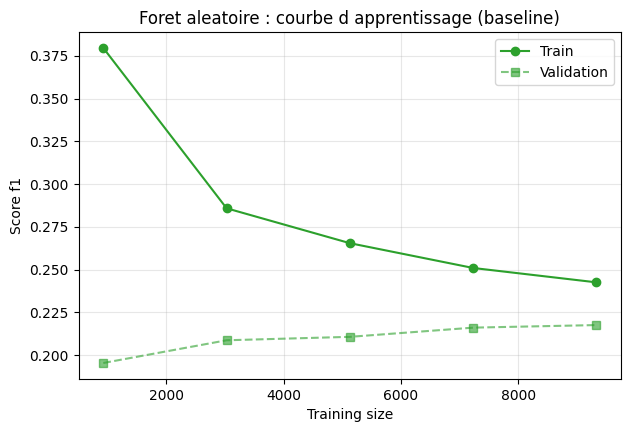


--- [Foret aleatoire] 3. recherche bayesienne (80 iterations)
[Foret aleatoire] Best CV f1 : 0.2219
[Foret aleatoire] Best parameters :
    model__max_depth                              4
    model__max_features                           0.4361169192854003
    model__max_samples                            0.996811997991172
    model__min_samples_leaf                       1
    model__min_samples_split                      17
    model__n_estimators                           370

--- [Foret aleatoire] 4. arbre individuel et importance des variables


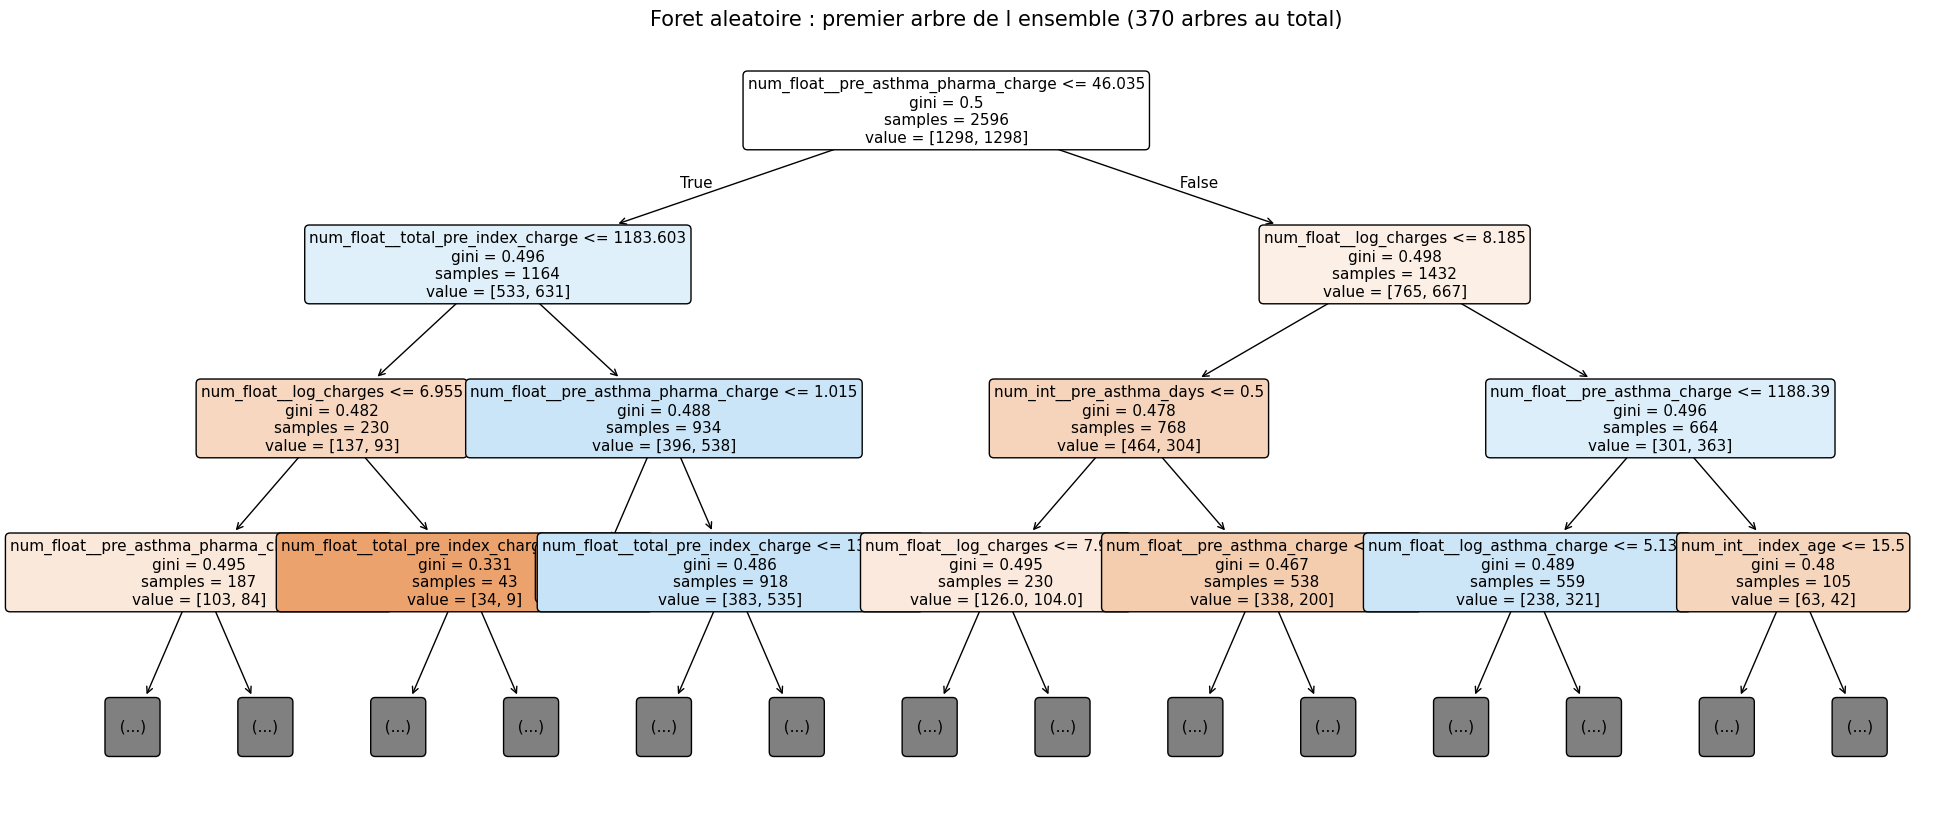

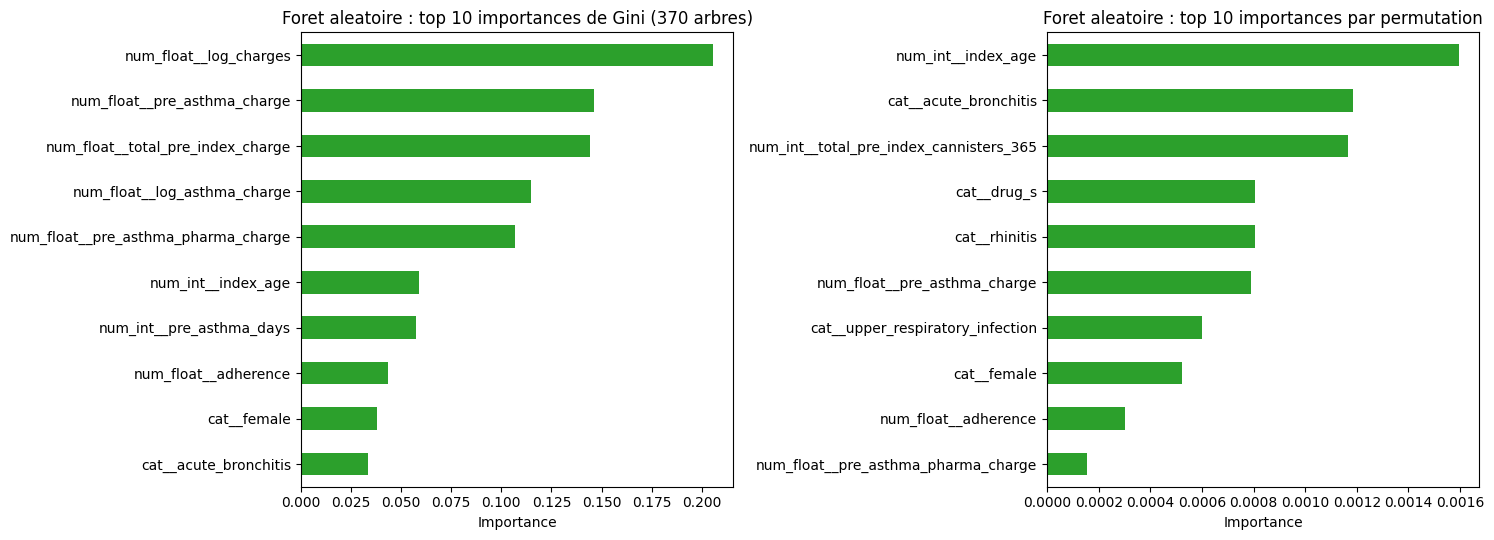


--- [Foret aleatoire] 5. reglage du seuil de decision
[Foret aleatoire] Seuil optimal (CV)        : 0.4960
[Foret aleatoire] CV f1 apres reglage du seuil : 0.2217


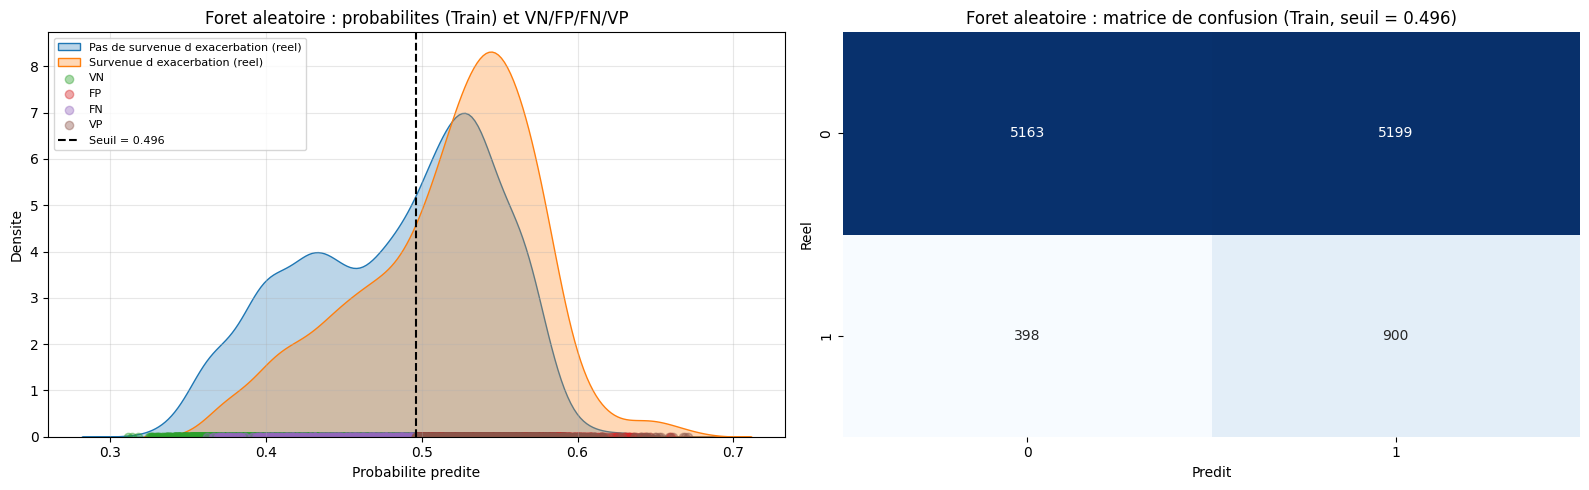


--- [Foret aleatoire] 6. evaluation sur le jeu de test
[Foret aleatoire] TEST F1        : 0.2360
[Foret aleatoire] TEST precision : 0.1460
[Foret aleatoire] TEST rappel    : 0.6154
[Foret aleatoire] TEST ROC-AUC   : 0.5588
              precision    recall  f1-score   support

           0       0.90      0.49      0.63      2551
           1       0.15      0.62      0.24       364

    accuracy                           0.50      2915
   macro avg       0.52      0.55      0.43      2915
weighted avg       0.80      0.50      0.58      2915


[Foret aleatoire] Duree totale : 12.6 min

Modeles evalues : ['Bagging', 'Boosting', 'Foret aleatoire']


In [40]:
RESULTATS = {}

for nom, config in MODELES.items():
    RESULTATS[nom] = evaluer_modele(nom, config)

print("Modeles evalues :", list(RESULTATS))

## 7. Comparaison des trois méthodes

### 7.1 Tableau récapitulatif

Les colonnes `CV` sont calculées sur le seul jeu d'entraînement, par validation croisée : ce sont elles qui servent à choisir. Les colonnes `test` mesurent la performance sur les 20 % de données mises de côté au tout début, jamais vues pendant l'apprentissage ni pendant le réglage.

In [41]:
recap = pl.DataFrame([
    {
        "methode": r["nom"],
        "F1 CV baseline": round(r["f1_cv"], 4),
        "AUC CV baseline": round(r["auc_cv"], 4),
        "F1 CV optimise": round(r["f1_cv_tuned"], 4),
        "seuil": round(r["seuil"], 4),
        "F1 CV + seuil": round(r["f1_cv_seuil"], 4),
        "F1 test": round(r["f1_test"], 4),
        "precision test": round(r["precision_test"], 4),
        "rappel test": round(r["recall_test"], 4),
        "AUC test": round(r["auc_test"], 4),
        "nb arbres": r["n_arbres"],
        "duree (min)": round(r["duree_s"] / 60, 1),
    }
    for r in RESULTATS.values()
])

recap

methode,F1 CV baseline,AUC CV baseline,F1 CV optimise,seuil,F1 CV + seuil,F1 test,precision test,rappel test,AUC test,nb arbres,duree (min)
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64
"""Bagging""",0.2168,0.5732,0.223,0.4984,0.2221,0.2364,0.1466,0.6099,0.5592,100,24.5
"""Boosting""",0.2158,0.573,0.2217,0.494,0.221,0.2383,0.1481,0.6099,0.5622,5970,86.5
"""Foret aleatoire""",0.2175,0.576,0.2219,0.496,0.2217,0.236,0.146,0.6154,0.5588,370,12.6


### 7.2 Courbes ROC et métriques superposées

La courbe ROC est tracée sur le jeu de test pour les trois méthodes. Elle ne dépend pas du seuil retenu : elle mesure la capacité de séparation brute. Les barres de droite, elles, dépendent du seuil, puisque précision, rappel et F1 se calculent sur des classes prédites.

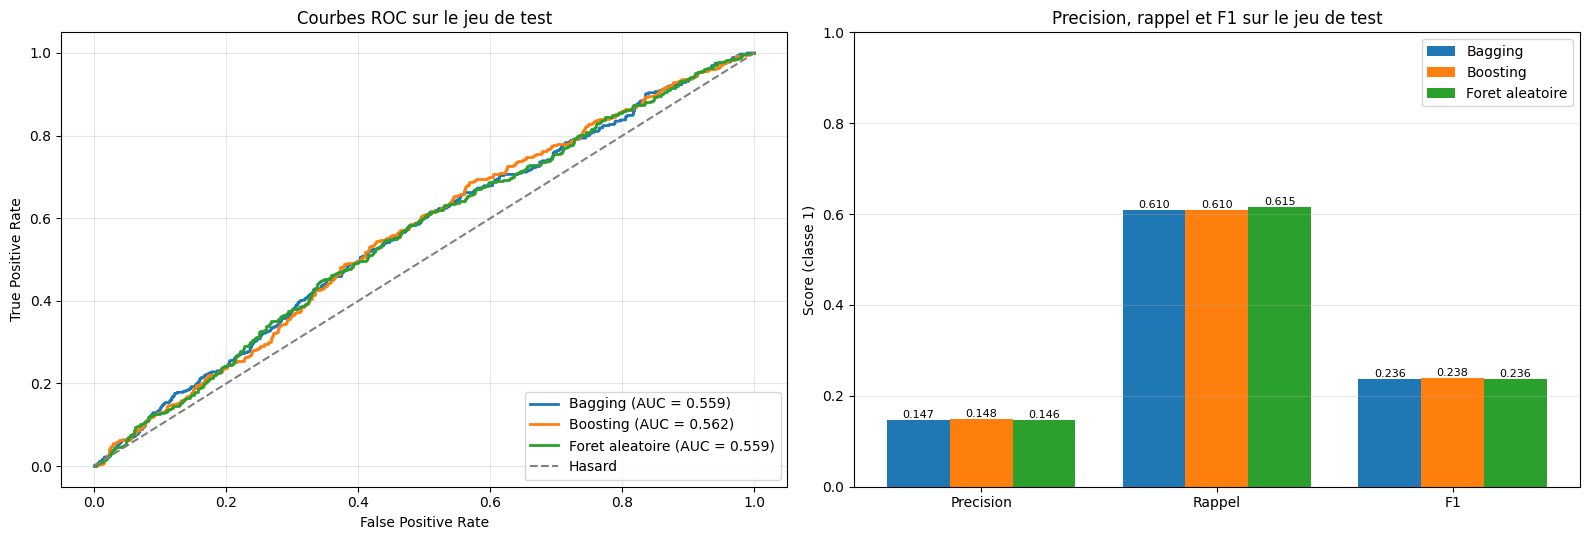

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# ---- Courbes ROC superposees (test)
for r in RESULTATS.values():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba_test"])
    axes[0].plot(fpr, tpr, linewidth=2, color=r["couleur"],
                 label=f"{r['nom']} (AUC = {r['auc_test']:.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Courbes ROC sur le jeu de test")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# ---- Barres groupees : precision, rappel, F1 (test)
metriques = ["precision_test", "recall_test", "f1_test"]
etiquettes = ["Precision", "Rappel", "F1"]
x = np.arange(len(metriques))
largeur = 0.8 / len(RESULTATS)

for i, r in enumerate(RESULTATS.values()):
    valeurs = [r[m] for m in metriques]
    position = x + i * largeur - 0.4 + largeur / 2
    barres = axes[1].bar(position, valeurs, largeur,
                         label=r["nom"], color=r["couleur"])
    axes[1].bar_label(barres, fmt="%.3f", fontsize=8)

axes[1].set_xticks(x, etiquettes)
axes[1].set_ylabel("Score (classe 1)")
axes[1].set_ylim(0, 1)
axes[1].set_title("Precision, rappel et F1 sur le jeu de test")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

### 7.3 Matrices de confusion côte à côte

Lire les trois matrices ensemble montre où chaque méthode place son compromis : un modèle très sensible remplit la colonne des positifs prédits, faux positifs compris.

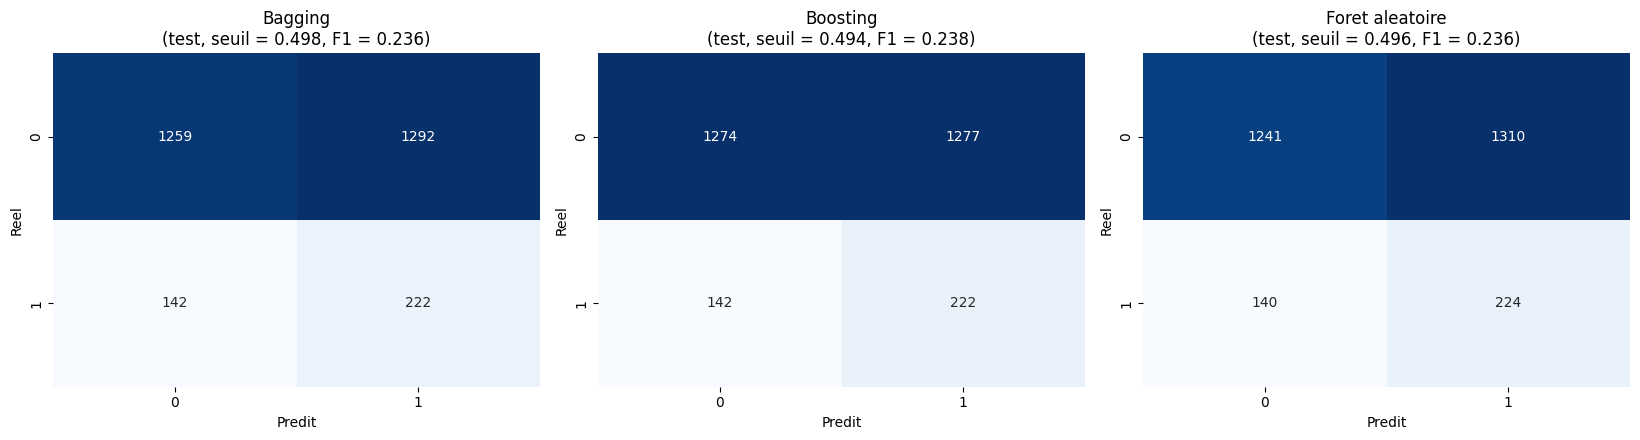

In [43]:
fig, axes = plt.subplots(1, len(RESULTATS), figsize=(5.5 * len(RESULTATS), 4.5))

for ax, r in zip(np.atleast_1d(axes), RESULTATS.values()):
    cm = confusion_matrix(y_test, r["y_pred_test"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_xlabel("Predit")
    ax.set_ylabel("Reel")
    ax.set_title(f"{r['nom']}\n(test, seuil = {r['seuil']:.3f}, F1 = {r['f1_test']:.3f})")

plt.tight_layout()
plt.show()

### 7.4 Les trois méthodes s'appuient-elles sur les mêmes variables ?

Si les trois méthodes désignent les mêmes variables, le signal est porté par les données et non par un artefact d'une méthode. Les importances sont comparées variable par variable, pour l'union des huit premières de chaque méthode.

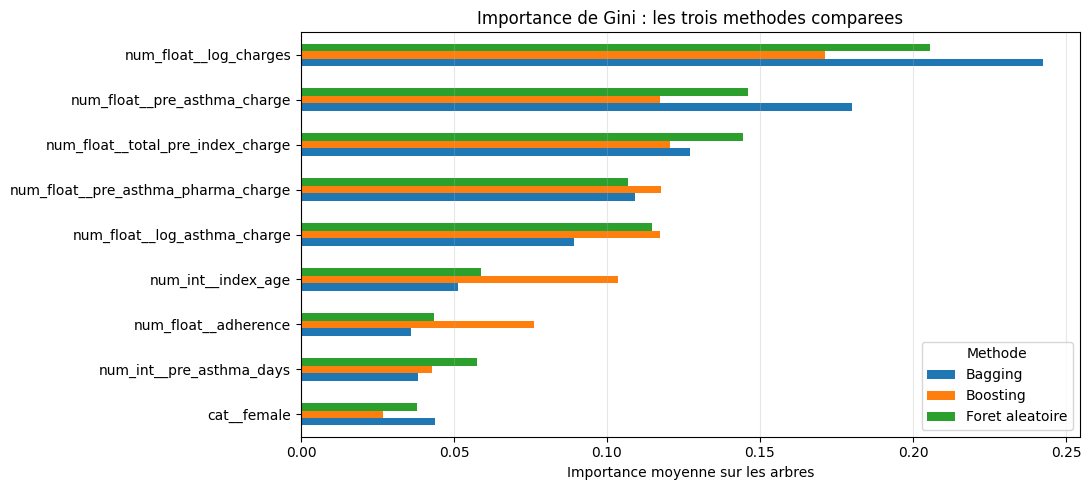

,Bagging,Boosting,Foret aleatoire
num_float__log_charges,0.2424,0.1712,0.2055
num_float__pre_asthma_charge,0.1800,0.1174,0.1462
num_float__total_pre_index_charge,0.1272,0.1204,0.1443
num_float__pre_asthma_pharma_charge,0.1091,0.1176,0.1069
num_float__log_asthma_charge,0.0891,0.1173,0.1149
num_int__index_age,0.0512,0.1035,0.0590
num_float__adherence,0.0359,0.0762,0.0434
num_int__pre_asthma_days,0.0383,0.0429,0.0574
cat__female,0.0437,0.0269,0.0380


In [44]:
# Union des 8 variables les plus importantes de chaque methode
variables_cles = []
for r in RESULTATS.values():
    for variable in r["importances_gini"].sort_values(ascending=False).head(8).index:
        if variable not in variables_cles:
            variables_cles.append(variable)

comparaison_gini = pd.DataFrame(
    {r["nom"]: r["importances_gini"].reindex(variables_cles) for r in RESULTATS.values()}
)

# tri par importance moyenne sur les trois methodes
comparaison_gini = comparaison_gini.loc[
    comparaison_gini.mean(axis=1).sort_values().index
]

couleurs = [r["couleur"] for r in RESULTATS.values()]

comparaison_gini.plot(
    kind="barh",
    figsize=(11, max(5, 0.45 * len(comparaison_gini))),
    color=couleurs,
)
plt.title("Importance de Gini : les trois methodes comparees")
plt.xlabel("Importance moyenne sur les arbres")
plt.legend(title="Methode")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

comparaison_gini.iloc[::-1].round(4)

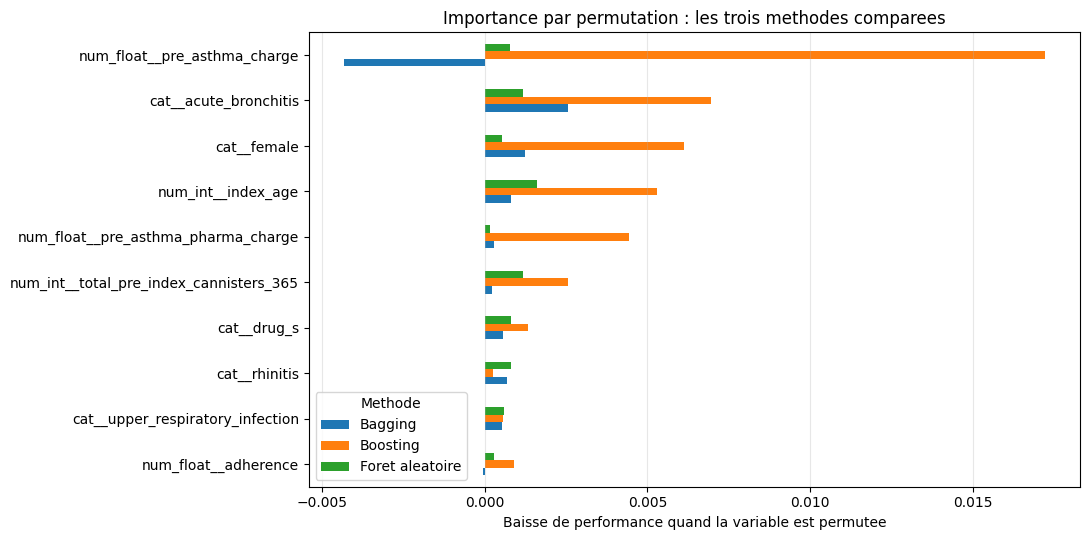

,Bagging,Boosting,Foret aleatoire
num_float__pre_asthma_charge,-0.0043,0.0172,0.0008
cat__acute_bronchitis,0.0026,0.0070,0.0012
cat__female,0.0013,0.0061,0.0005
num_int__index_age,0.0008,0.0053,0.0016
num_float__pre_asthma_pharma_charge,0.0003,0.0044,0.0002
num_int__total_pre_index_cannisters_365,0.0002,0.0026,0.0012
cat__drug_s,0.0006,0.0013,0.0008
cat__rhinitis,0.0007,0.0003,0.0008
cat__upper_respiratory_infection,0.0005,0.0006,0.0006
num_float__adherence,-0.0001,0.0009,0.0003


In [45]:
# Meme comparaison, avec les importances par permutation
comparaison_perm = pd.DataFrame(
    {r["nom"]: r["importances_permutation"] for r in RESULTATS.values()}
)

comparaison_perm = comparaison_perm.loc[
    comparaison_perm.mean(axis=1).sort_values(ascending=False).head(10).index
]

comparaison_perm.iloc[::-1].plot(kind="barh", figsize=(11, 5.5), color=couleurs)
plt.title("Importance par permutation : les trois methodes comparees")
plt.xlabel("Baisse de performance quand la variable est permutee")
plt.legend(title="Methode")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

comparaison_perm.round(4)

### 7.5 Courbes d'apprentissage superposées

Les trois courbes au même endroit disent si le plafond observé tient à la méthode ou aux données : trois paires de courbes basses et jointes désignent les données, non l'algorithme.

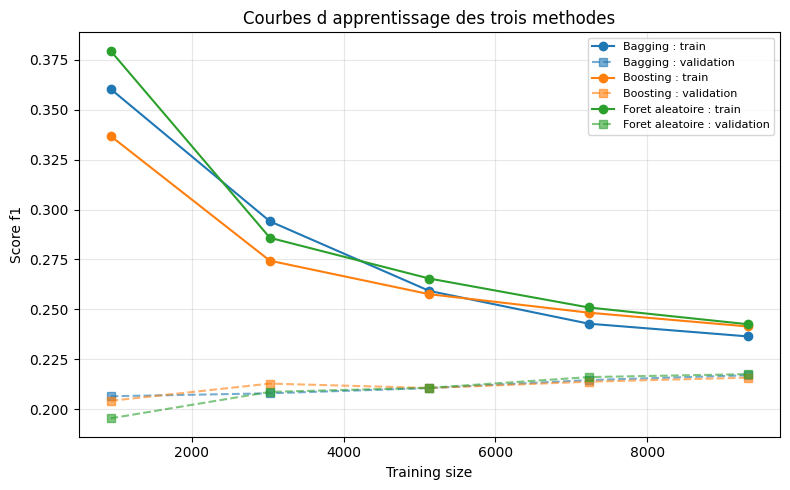

In [46]:
plt.figure(figsize=(8, 5))

for r in RESULTATS.values():
    courbe = r["courbe_apprentissage"]
    plt.plot(courbe["tailles"], courbe["scores_train"], marker="o",
             color=r["couleur"], label=f"{r['nom']} : train")
    plt.plot(courbe["tailles"], courbe["scores_val"], marker="s", linestyle="--",
             color=r["couleur"], alpha=0.6, label=f"{r['nom']} : validation")

plt.xlabel("Training size")
plt.ylabel(f"Score {SCORING}")
plt.title("Courbes d apprentissage des trois methodes")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.6 Lecture des résultats

**Des performances quasi identiques.** Les trois méthodes aboutissent à des scores presque confondus. En validation croisée, après réglage du seuil, le F1 vaut 0,2221 pour le bagging, 0,2210 pour le boosting et 0,2217 pour la forêt aléatoire, soit un écart d'un millième, bien inférieur à la variabilité attendue d'un *fold* à l'autre. Sur le jeu de test, le F1 reste compris entre 0,236 et 0,238 et l'AUC entre 0,559 et 0,562. Les courbes ROC de la section 7.2 se superposent et restent proches de la diagonale du hasard. Aucune des trois familles de méthodes ne trouve donc dans ces variables de quoi séparer nettement les patients qui feront une exacerbation de ceux qui n'en feront pas  la limite tient aux données, non au choix de l'algorithme.

**Un biais élevé plutôt qu'un surapprentissage.** Les courbes d'apprentissage de la section 7.5 ont la même forme pour les trois méthodes. Le score d'entraînement baisse de 0,34 à 0,38 sur 1 000 patients jusqu'à 0,24 environ sur 9 300 patients, tandis que le score de validation ne progresse que de 0,20 à 0,217. L'écart final entre les deux courbes, de l'ordre de 0,02 à 0,03, est faible, et les deux courbes convergent à un niveau bas  le modèle est en sous-apprentissage. La recherche bayésienne le confirme, puisqu'elle retient des arbres peu profonds (profondeur 3 pour le bagging, 4 pour la forêt aléatoire) qui limitent la variance sans pouvoir créer un signal absent. On attendait davantage du boosting, qui agit sur le biais, mais il n'apporte aucun gain mesurable, ce qui renforce l'hypothèse d'une limite propre aux variables disponibles. La légère pente encore positive de la courbe de validation laisse penser que des données supplémentaires amélioreraient un peu le score, sans en changer l'ordre de grandeur.

**Un compromis orienté vers le rappel, au prix de nombreuses fausses alertes.** Les trois seuils retenus sont proches de 0,5 (0,498, 0,494 et 0,496), car les classifieurs équilibrés rééchantillonnent déjà les classes pendant l'apprentissage. Sur les 364 patients du jeu de test qui ont fait une exacerbation, chaque méthode en repère 222 ou 224, soit un rappel d'environ 61 . En contrepartie, elle signale à tort près de 1 300 patients sur les 2 551 qui n'en ont pas fait. La précision de 0,15 n'est guère supérieure à la prévalence de l'événement dans le jeu de test (364 sur 2 915, soit 12,5 )  signaler un patient au hasard donnerait une précision de 12,5 , et le modèle ne fait que légèrement mieux. Dans un usage de dépistage, il permettrait de cibler environ la moitié des patients pour retrouver six exacerbations sur dix, ce qui reste un tri grossier.

**Des variables importantes concordantes, mais un signal faible.** Selon l'importance de Gini (section 7.4), les trois méthodes placent en tête les mêmes variables, à savoir les coûts de santé antérieurs (`log_charges`, `pre_asthma_charge`, `total_pre_index_charge`, `pre_asthma_pharma_charge`, `log_asthma_charge`), suivis de l'âge et de l'adhérence au traitement. Cette concordance indique que le signal, aussi modeste soit-il, est porté par les données. Il faut néanmoins garder à l'esprit que l'importance de Gini favorise les variables continues, qui offrent beaucoup de points de coupure. Les importances par permutation, qui mesurent la baisse réelle de performance, sont toutes inférieures à 0,02 et parfois négatives, ce qui signifie qu'aucune variable ne porte à elle seule une part notable de la prédiction. Le boosting est la méthode qui s'appuie le plus nettement sur certaines variables, en particulier `pre_asthma_charge`, `acute_bronchitis`, le sexe et l'âge.

**Le coût de calcul départage les méthodes.** À performance équivalente, la durée d'exécution devient le critère le plus parlant. La forêt aléatoire termine en 12,6 minutes, le bagging en 24,5 minutes et le boosting en 86,5 minutes, ce dernier entraînant près de 6 000 arbres contre 100 pour le bagging et 370 pour la forêt aléatoire. La règle de sélection de la section 8, fondée sur le seul F1 en validation croisée, retient le bagging, mais son avance sur la forêt aléatoire (0,0004) relève du bruit. Pour un modèle de même qualité, la forêt aléatoire serait un choix tout aussi défendable compte tenu de sa rapidité.

## 8. Modèle retenu, export et prédiction

Le modèle retenu est celui qui obtient le meilleur F1 en validation croisée après réglage du seuil, donc sur le seul jeu d'entraînement. Sélectionner sur le jeu de test donnerait un score flatteur mais biaisé : le test aurait alors servi à choisir, et ne mesurerait plus la performance sur des données inconnues. Le score de test du modèle retenu est rapporté ensuite, sans entrer dans la décision.

In [47]:
nom_retenu = max(RESULTATS, key=lambda nom: RESULTATS[nom]["f1_cv_seuil"])
retenu = RESULTATS[nom_retenu]

modele_final = retenu["threshold_tuner"]

print("Methode retenue :", nom_retenu)
print(f"  F1 CV + seuil : {retenu['f1_cv_seuil']:.4f}")
print(f"  seuil         : {retenu['seuil']:.4f}")
print(f"  F1 test       : {retenu['f1_test']:.4f}")
print(f"  AUC test      : {retenu['auc_test']:.4f}")
print("  hyperparametres :")
for cle, valeur in retenu["best_params"].items():
    print(f"    {cle:<45} {valeur}")

Methode retenue : Bagging
  F1 CV + seuil : 0.2221
  seuil         : 0.4984
  F1 test       : 0.2364
  AUC test      : 0.5592
  hyperparametres :
    model__estimator__max_depth                   3
    model__estimator__min_samples_leaf            11
    model__max_samples                            0.6471258997869709
    model__n_estimators                           100


In [48]:
modele_final

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",StratifiedKFo... shuffle=True)
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary `.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like 

***Diagramme du pipeline retenu***

In [49]:
# Activer affichage diagramme
set_config(display="diagram")

DOSSIER_OUTPUTS.mkdir(parents=True, exist_ok=True)

chemin_html = DOSSIER_OUTPUTS / "pipeline_projet1_comparaison.html"
chemin_html.write_text(estimator_html_repr(modele_final), encoding="utf-8")

print("Diagramme ecrit dans :", chemin_html)

Diagramme ecrit dans : c:\Users\Abdo\OneDrive\Documents\Projet\Data Challenge 2\outputs\pipeline_projet1_comparaison.html


***Sérialisation du modèle***

Le modèle est écrit sous un nom propre à ce notebook, afin de ne pas écraser `models/final_model.pkl` produit par les notebooks précédents.

In [50]:
DOSSIER_MODELS.mkdir(parents=True, exist_ok=True)

chemin_modele = DOSSIER_MODELS / "best_model_projet1_comparaison.pkl"
joblib.dump(modele_final, chemin_modele)

print("Modele ecrit dans :", chemin_modele)

Modele ecrit dans : c:\Users\Abdo\OneDrive\Documents\Projet\Data Challenge 2\models\best_model_projet1_comparaison.pkl


***Prédiction sur un nouveau fichier***

Le *pipeline* contient le préprocessing : un fichier de même structure que `trainDataDC2.csv.gz` peut lui être passé tel quel, sans préparation préalable.

In [51]:
# Charger le modele.
# joblib.load execute du code a la deserialisation : ne charger que des fichiers
# produits par ce projet. Ici, c est celui qui vient d etre ecrit juste au-dessus.
modele_charge = joblib.load(chemin_modele)

# Charger le nouveau fichier (ici le fichier d entrainement, a titre de demonstration)
df_nouveau = pl.read_csv(CHEMIN_DATA)

# Extraire patid
patid = df_nouveau["patid"]

# Preparer le nouveau fichier : le ColumnTransformer selectionne les colonnes par leur nom
X_new = df_nouveau.drop("patid")

# Prediction
prediction = modele_charge.predict(X_new)

# Construire le resultat
resultat_predictions = pl.DataFrame({
    "patid": patid,
    "prediction": prediction,
})

# Sauvegarder
chemin_predictions = DOSSIER_OUTPUTS / "predictions_projet1_comparaison.csv"
resultat_predictions.write_csv(chemin_predictions)

print("Fichier genere avec succes :", chemin_predictions)
resultat_predictions.head()

Fichier genere avec succes : c:\Users\Abdo\OneDrive\Documents\Projet\Data Challenge 2\outputs\predictions_projet1_comparaison.csv


patid,prediction
i64,i32
1073754155,0
1073799394,1
1073854918,0
1073898249,1
1073913003,0
